<a href="https://drive.google.com/file/d/1-lmvLqHRoVztabnwQ8RbZuDhpsd1kmYY/view?usp=sharing" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Lab 1** for the course of *Selected Topics in Music and Acoustic Engineering* :

***Machine Learning for Audio and Acoustic Engineering***
---

* Student 1: Jorge Cuartero Galindo
* Student 2: Giuliano Di Lorenzo

# **Before you start**

*   Go to "*File*" --> "*Save a copy in Drive*"
*   Open that copy (might open automatically)
*   Then continue below


**Import libraries**

* We need a number of libraries. Import them once to use throughout the document.

In [180]:
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8")
import librosa, librosa.display
import IPython

# **Lab 1: Basic Audio Processing in Python**

Python is a general-purpose programming language that is popular and easy to use. For new programmers, it is a great choice as a first programming language. In fact, more and more university CS departments are centering their introductory courses around Python.


#### **The Python Tutorial**

If you are new to Python, you can follow this [Python Tutorial](https://docs.python.org/3.8/tutorial/index.html).

For the purposes of this course, be sure you understand the following sections:

Section 3: *An Informal Introduction to Python*

*   numbers: int, float
*   strings
*   lists

Section 4: *More Control Flow Tools*

*   if statements
*   for statements
*   range
*   functions

Section 5: *Data Structures*

*   list comprehensions
*   tuples
*   dictionaries
*   looping techniques


Other resources:

*   [The Hitchhiker's Guide to Python](http://docs.python-guide.org/en/latest/)
*   [SciPy Lecture Notes](http://www.scipy-lectures.org/)
*   [SciPy Lecture Notes](http://www.scipy-lectures.org/)
*   [learnpython.org](https://www.learnpython.org/)


### **Exercise 1**: Basic operations with arrays

Use numpy to do the following array operations:

* Create a row vector v1: $[1,\, 2,\, 3]$ with shape (1,3)

In [181]:
v1 = np.array([[1,2,3]])
print(v1)
print(v1.shape)

[[1 2 3]]
(1, 3)


Expected output:
```
(1, 3)
```

* Create a column vector v2:  $[1,\, 2,\, 3]^T$

In [182]:
v2 = np.array([[1],[2],[3]])
print(v2)
print(v2.shape)

[[1]
 [2]
 [3]]
(3, 1)


Expected output:
```
(3, 1)
```

* Create a matrix M of 3 x 3 of random integer elements:

In [183]:
M = np.random.randint(10, size=(3,3))
print(M)
print(np.shape(M))

[[8 7 6]
 [0 1 9]
 [6 1 5]]
(3, 3)


* Show the first row of M:

In [184]:
print(M[0,:])   # does not keep dimension
print(M[0:1,:]) # keeps dimension

[8 7 6]
[[8 7 6]]


* Show the first column of M:

In [185]:
print(M[:,0])   # does not keep dimension
print(M[:,0:1]) # keeps dimension

[8 0 6]
[[8]
 [0]
 [6]]


* Perform the matrix product v2 times v1:

In [186]:
print(np.dot(v2,v1))    # 3x1 * 1x3 = 3x3
print(v2 @ v1)          # 3x1 * 1x3 = 3x3

[[1 2 3]
 [2 4 6]
 [3 6 9]]
[[1 2 3]
 [2 4 6]
 [3 6 9]]


* Perform the matrix product v1 times v2:

In [187]:
print(np.dot(v1,v2))    # 1x3 * 3x1 = 1x1
print(v1 @ v2)          # 1x3 * 3x1 = 1x1

[[14]]
[[14]]


* Perform the element-wise multiplication of v2 and v1, with result having the shape of v2:

In [188]:
print(np.multiply(v2,v1.T))     # 3x1 * (1x3).T = 3x1
print(v2*v1.T)                  # 3x1 * (1x3).T = 3x1

[[1]
 [4]
 [9]]
[[1]
 [4]
 [9]]


* Perform the element-wise multiplication of v1 and v2, with result having the shape of v1:

In [189]:
print(np.multiply(v1,v2.T))     # (3x1).T * 1x3 = 1x3
print(v1*v2.T)                  # (3x1).T * 1x3 = 1x3

[[1 4 9]]
[[1 4 9]]


* Generate an array of 20 equally-spaced numbers between 0 and 10:

In [190]:
print(np.linspace(0,10,20)) # from 0 to 10 with 20 points

[ 0.          0.52631579  1.05263158  1.57894737  2.10526316  2.63157895
  3.15789474  3.68421053  4.21052632  4.73684211  5.26315789  5.78947368
  6.31578947  6.84210526  7.36842105  7.89473684  8.42105263  8.94736842
  9.47368421 10.        ]


Expected output:
```
[ 0.          0.52631579  1.05263158  1.57894737  2.10526316  2.63157895
  3.15789474  3.68421053  4.21052632  4.73684211  5.26315789  5.78947368
  6.31578947  6.84210526  7.36842105  7.89473684  8.42105263  8.94736842
  9.47368421 10.        ]
```

* Generate an array of numbers going from 0 to 1.5 in steps of 0.2:

In [191]:
np.arange(0,1.5,0.2)    # from 0 to 1.5 with a step of 0.2

array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4])

Expected output:
```
array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4])
```

* Generate an array of 13 logarithmically-spaced numbers between 1 and 2 (both included) using the numpy function logspace()

In [192]:
np.logspace(np.log10(1),np.log10(2),13)     # from 1 (=np.log10(1)) to 2 (=np.log10(2)) with 13 points
# np.logspace(0,1, num = 13, base = 2)     # alternative

array([1.        , 1.05946309, 1.12246205, 1.18920712, 1.25992105,
       1.33483985, 1.41421356, 1.49830708, 1.58740105, 1.68179283,
       1.78179744, 1.88774863, 2.        ])

Expected output:
```
array([1.        , 1.05946309, 1.12246205, 1.18920712, 1.25992105,
       1.33483985, 1.41421356, 1.49830708, 1.58740105, 1.68179283,
       1.78179744, 1.88774863, 2.        ])
```

* Generate the same array of 13 logarithmically-spaced numbers using fractional powers of 2 (i.e. ```2**...```):


In [193]:
2**np.linspace(0, 1, 13)    # from 1 (=2**0) to 2 (=2**1) with 13 points

array([1.        , 1.05946309, 1.12246205, 1.18920712, 1.25992105,
       1.33483985, 1.41421356, 1.49830708, 1.58740105, 1.68179283,
       1.78179744, 1.88774863, 2.        ])

Expected output:
```
array([1.        , 1.05946309, 1.12246205, 1.18920712, 1.25992105,
       1.33483985, 1.41421356, 1.49830708, 1.58740105, 1.68179283,
       1.78179744, 1.88774863, 2.        ])
```

The generated array divides logarithmically an octave and can be used to generate fundamental frequencies for the pitches:

Index | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12
---| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | ---
Pitch | A | A# | B | C | C# | D | D# | E | F | F# | G | G# | A$_2$  



* Use as a starting fundamental frequency, the one corresponding to A (440 Hz), and generate an array with the fundamental frequencies of each pitch:

In [194]:
fk = 440*(2**np.linspace(0, 1, 13))
print(fk)

##The following two ways of computing are equivalent

#print(np.logspace(np.log10(440), np.log10(880), 13))
#print(440*(np.logspace(0, 1,num = 13, base = 2)))

[440.         466.16376152 493.88330126 523.2511306  554.36526195
 587.32953583 622.25396744 659.25511383 698.45646287 739.98884542
 783.99087196 830.60939516 880.        ]


Expected output:
```
[440.         466.16376152 493.88330126 523.2511306  554.36526195
 587.32953583 622.25396744 659.25511383 698.45646287 739.98884542
 783.99087196 830.60939516 880.        ]
```

### **Exercise 2**: Generation of notes

Assume a sampling frequency of fs = 16000 Hz, and generate a time vector with sampling instants between 0 s and 2 s:

In [195]:
fs = 16000
dur = 2
t = np.linspace(0,dur,fs*dur)
# t = np.arange(0,dur,1/fs)     # alternative
print(t)

[0.00000000e+00 6.25019532e-05 1.25003906e-04 ... 1.99987500e+00
 1.99993750e+00 2.00000000e+00]


Expected output:
```
[0.0000000e+00 6.2500000e-05 1.2500000e-04 ... 1.9998125e+00 1.9998750e+00
 1.9999375e+00]
```

### Tasks:
* Generate an array containing the envelope shape:

\begin{equation}
  a(t) = Ae^{-t/\tau}
\end{equation}

with $\tau = 0.4$, $A=0.5$ and $t$ corresponding to a given time instant:

In [196]:
tau = 0.4
A = 0.5
a = A*np.exp(-t/tau)
print(f'a = {a}')

a = [0.5        0.49992188 0.49984377 ... 0.00337003 0.0033695  0.00336897]


Expected output:
```
a = [0.5        0.49992188 0.49984377 ... 0.00337055 0.00337003 0.0033695 ]
```

* Plot the envelope using Matplotlib:

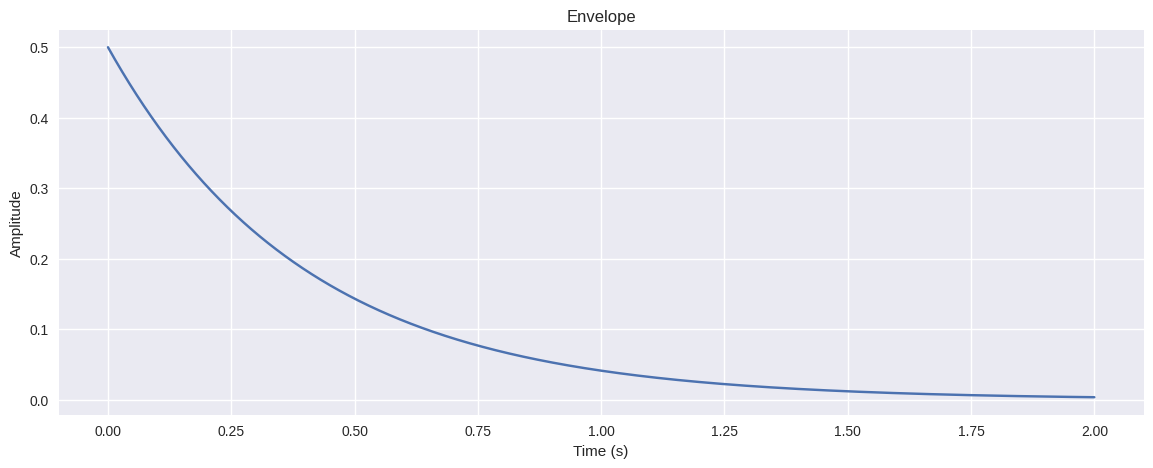

In [197]:
plt.figure(figsize=(14,5))
plt.plot(t,a)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Envelope')
plt.show()

* Generate a sawtooth wave by using ```scipy.signal``` to generates notes with the model

\begin{equation}
  x(t) = a(t) \textrm{sawtooth}(2\pi f_k t)
\end{equation}

where $a(t)$ is the envelope (see above) and $f_k$ the fundamental frequencies of the $k$-th pitch as in the table of Exercise 1.

Generate note signals for pitches A, C#, E and A$_2$:

In [198]:
# each note is stored in a row of the matrix, being the note A the first row
x = signal.sawtooth(2*np.pi*fk.reshape(-1,1)*t)*a

import IPython.display as ipd

* Listen to each of the notes by using ``IPython.display.display(IPython.display.Audio(x, rate=fs))``

In [199]:
ipd.Audio(x[0,:], rate=fs) # A

In [200]:
ipd.Audio(x[4,:], rate=fs) # C#

In [201]:
ipd.Audio(x[7,:], rate=fs) # E

In [202]:
ipd.Audio(x[12,:], rate=fs) # A2

* Generate a vector arpegio by concatenating the four notes:

In [203]:
arpeggio = np.concatenate((x[0,:],x[4,:],x[7,:],x[12,:]))
ipd.Audio(arpeggio, rate=fs)

* Generate a vector chord made by summing up the four notes and dividing
them by 4 to avoid clipping:

In [204]:
chord = (x[0,:]+x[4,:]+x[7,:]+x[12,:])/4
ipd.Audio(chord, rate=fs)

### **Exercise 3**: STFT Representation

Now let's download a speech signal using the wget command. Then, we are going to read it with using ```librosa.load``` and show its sampling rate and duration.

Note 1: The audio file can be also downloaded and imported into you colab space manually.

Note 2: By default, ```librosa.load``` resample the input signal to 22050Hz. If we want to keep the original sampling frequency, then use ```sr=None```.

In [205]:
!pip install wget
!wget -P sample_data/ https://www.voiptroubleshooter.com/open_speech/american/OSR_us_000_0010_8k.wav

--2025-03-17 18:04:35--  https://www.voiptroubleshooter.com/open_speech/american/OSR_us_000_0010_8k.wav
Resolving www.voiptroubleshooter.com (www.voiptroubleshooter.com)... 162.241.218.124
Connecting to www.voiptroubleshooter.com (www.voiptroubleshooter.com)|162.241.218.124|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 538014 (525K) [audio/x-wav]
Saving to: ‘sample_data/OSR_us_000_0010_8k.wav.3’

OSR_us_000_0010_8k. 100%[===================>] 525.40K  1.55MB/s    in 0.3s    

2025-03-17 18:04:35 (1.55 MB/s) - ‘sample_data/OSR_us_000_0010_8k.wav.3’ saved [538014/538014]



In [206]:
signal, sample_rate = librosa.load('sample_data/OSR_us_000_0010_8k.wav', sr=None)
print(f'Sample rate: {sample_rate}')
duration=signal.size/sample_rate;
print(f'Signal duration: {duration}')
IPython.display.Audio(signal, rate=sample_rate)

Sample rate: 8000
Signal duration: 33.623125


Expected output:
```
Sample rate:  8000
Signal duration 33.623125
```

### Taks:
* Cut the signal to show only the third spoken sentence (from t=7 s to t = 10 s). Represent it with respect to time in seconds.

Text(0.5, 1.0, 'Signal cut from 7 to 10 s')

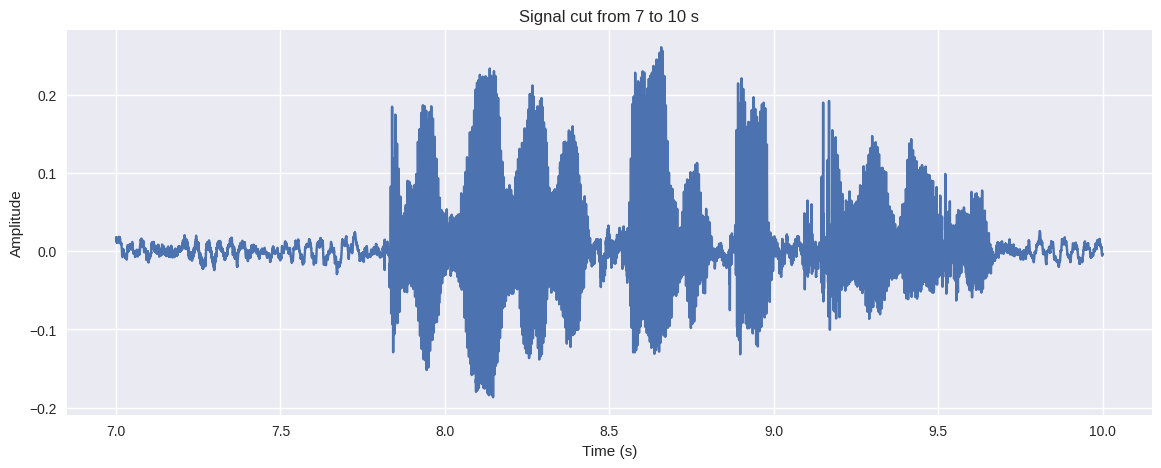

In [207]:
cut_audio = signal[7*sample_rate:10*sample_rate]
# alternative
# t2 = np.linspace(7,10,int(sample_rate*(10-7)))
t3 = np.arange(7,10,1/sample_rate)

plt.figure(figsize=(14,5))
plt.plot(t3,cut_audio)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Signal cut from 7 to 10 s')

### Observation

The time axis in this plot goes from 7 to 10 seconds, but later on it will change from 0 to 3 seconds. The selected audio portion remains the very same.

* Now listen to the selected audio segment:

In [208]:
IPython.display.Audio(cut_audio, rate=sample_rate)

Create a function "enframe" that takes as input:

*   signal (one-dimensional)
*   frame length (in samples)
*   hop size (in samples)

and returns a matrix where each column stores a frame of the signal. The function should pad the signal with zeroes if necessary.

Here is the pseudocode:



```
FUNCTION enframe(signal, frame_length, hop_size)
    INPUT:
        signal: Array containing the audio signal samples
        frame_length: Integer, the number of samples per frame
        hop_size: Integer, the number of samples to step between frames
    OUTPUT:
        frames: 2D Array where each column is a frame of the signal

    INITIALIZE empty list frames

    CALCULATE total_frames = CEIL((length of signal - frame_length) / hop_size) + 1

    CALCULATE padding_needed = (total_frames - 1) * hop_size + frame_length - length of signal

    IF padding_needed > 0 THEN
        APPEND padding_needed zeros to signal

    FOR i FROM 0 TO total_frames - 1
        START_INDEX = i * hop_size
        END_INDEX = START_INDEX + frame_length

        APPEND signal[START_INDEX:END_INDEX] TO frames

    RETURN frames
END FUNCTION
```

In [209]:
def enframe(signal, frame_length, hop_size):
    """
    INPUT:
        signal:         Array containing the audio signal samples
        frame_length:   Integer, the number of samples per frame
        hop_size:       Integer, the number of samples to step between frames
    OUTPUT:
        frames:         2D Array where each column is a frame of the signal
    """

    frames = []

    # number of frames that fit into "signal"
    total_frames = np.ceil((len(signal) - frame_length) / hop_size) + 1

    # number of zeros to complete the last frames
    padding_needed = (total_frames - 1) * hop_size + frame_length - len(signal)

    # pad if necessary
    if padding_needed > 0:
        signal = np.append(signal, np.zeros(int(padding_needed)))

    # frames computation
    for i in range(int(total_frames)):
        start_index = i * hop_size
        end_index = start_index + frame_length
        # all frame arrays are stored into an array
        frames.append(signal[start_index:end_index])

    # convertion of a list of lists into a matrix and transposition
    frames = np.vstack(frames).T        # each column is a different frame

    return frames

* Divide the signal into frames of length 512, using a hop size of 256 samples. Show the dimensions of the output.

In [210]:
frame_length= 512
hop_size = 256
frames = enframe(cut_audio, frame_length, hop_size)
print(np.shape(frames))

(512, 93)


Expected output:
```
shape = (512, 93)
```

* Plot the content of the 10-th frame:

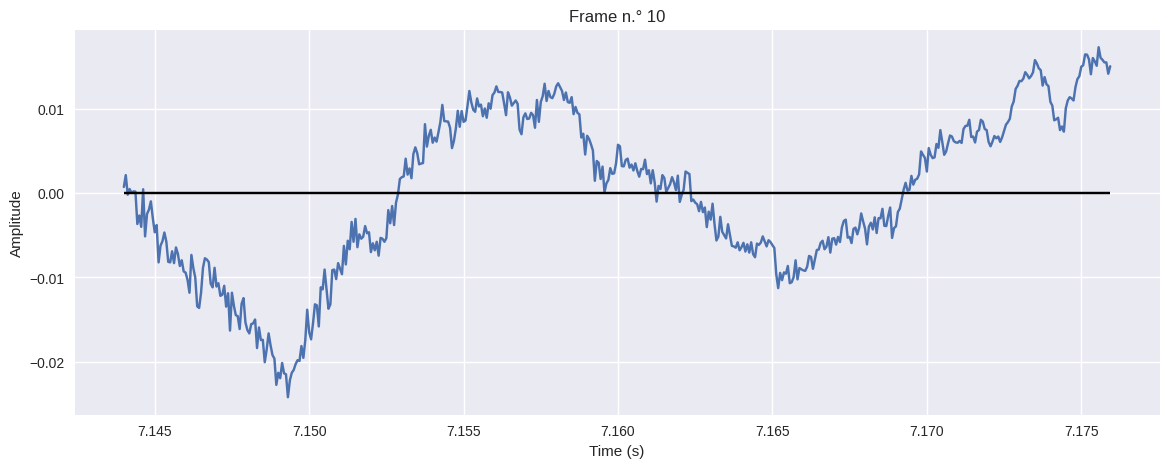

In [211]:
n_window = 10   # number of selected frame (index = n_window-1)
t_10 = 7 + (np.arange(frame_length)+hop_size*(n_window-1))/fs   # time interval

plt.figure(figsize=(14,5))
plt.plot(t_10, frames[:,n_window-1])
plt.title(f'Frame n.° {n_window}')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.hlines(y=0, xmin=t_10[0], xmax=t_10[-1], colors='black')

* Create a Hamming function and apply it to each of your frames:

In [212]:
winfunc = np.hamming(frame_length).reshape(-1, 1)   # Hamming window function
windowed_signal = frames * winfunc  # smoothing already-cut frames

* Plot again the 10-th frame after having applied your Hamming window:

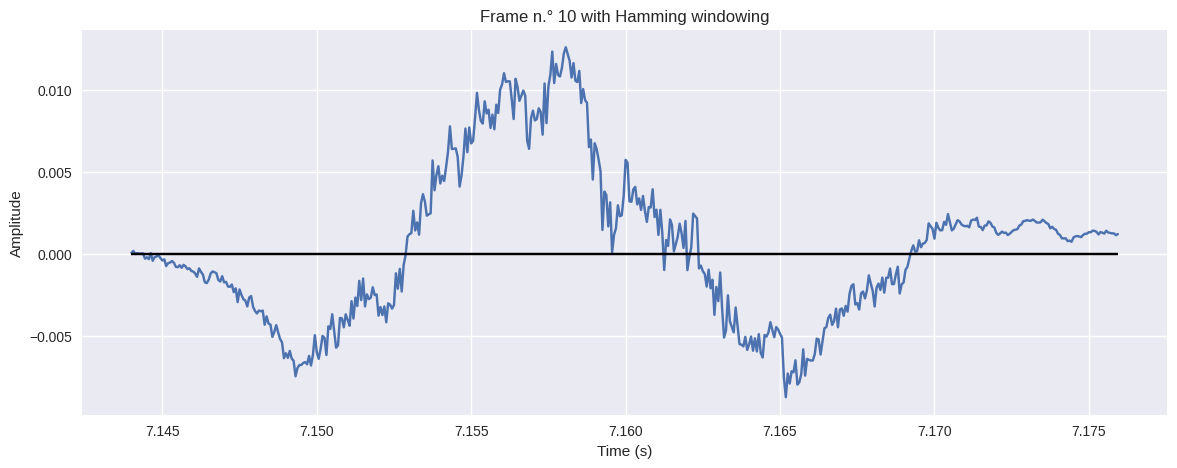

In [213]:
plt.figure(figsize=(14,5))
plt.plot(t_10, windowed_signal[:,n_window-1])
plt.title(f'Frame n.° {n_window} with Hamming windowing')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.hlines(y=0, xmin=t_10[0], xmax=t_10[-1], colors='black')

* Compute the DFT of each column (frame) using numpy's ```rfft()``` function. Use as number of FFT points the same value as window length.

In [214]:
NFFT = frame_length     # frame length = window length
DFT = np.fft.rfft(windowed_signal, NFFT, axis=0)    # FFT of each column
print(np.shape(DFT))        # only positive frequencies

(257, 93)


* Use the following function to represent the result with the indices of each frame and each frequency bin in the horizontal and vertical axes, respectively.



In [215]:
def show_specgram(X,ratio,limits,cmin):
  '''This function represents matrix X within a figure having the desired
  aspect ratio.
  Input:
    - X: matrix to represent
    - ratio: aspect ratio of axes
    - limits: array with [xmin, xmax, ymax, ymin] (y axis is reversed)
    - cmin: minimum value corresponding to the bottom of the colormap scale.
  Output:
    - figure handle
  '''
  w, h = plt.figaspect(ratio);
  fig = plt.figure(figsize=(w*2, h*2))
  ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
  im = ax.imshow(X, extent = limits, cmap='viridis', interpolation='none')
  xleft, xright = ax.get_xlim()
  ybottom, ytop = ax.get_ylim()
  ax.set_aspect(abs((xright-xleft)/(ybottom-ytop))*ratio)
  ax.invert_yaxis()
  if cmin != None:
    cbar = plt.colorbar(im)
    cbar.mappable.set_clim(cmin, None)
  return ax

* Now let's use the function ```show_spectrogram```to display the log power spectrogram ```(10*np.log10(np.abs(X)**2)```.

Note: User parameters ratio=0.7 and  cmin=-50

Text(0.5, 0, 'Frame index')

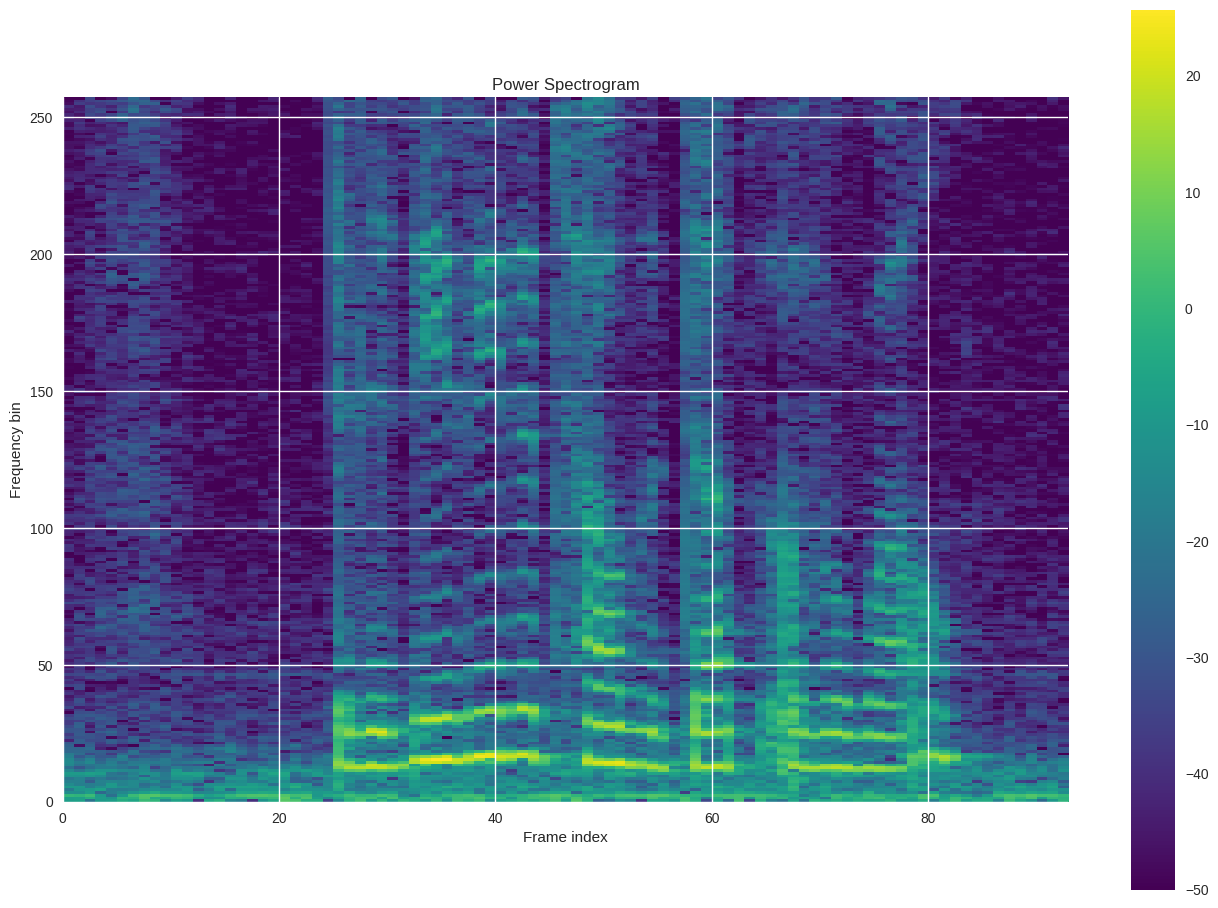

In [216]:
# plot of spectogram = |FFT{sig}|^2 (in dB)
ax = show_specgram(10 * np.log10(np.abs(DFT)**2), ratio=0.7,
                   limits=[0,np.shape(DFT)[1],np.shape(DFT)[0],0], cmin=-50)
ax.set_title('Power Spectrogram')
ax.set_ylabel('Frequency bin')
ax.set_xlabel('Frame index')

* Finally, represent again the spectrogram but as a function of the time in seconds and frequency in Hz.

Text(0.5, 0, 'Time (s)')

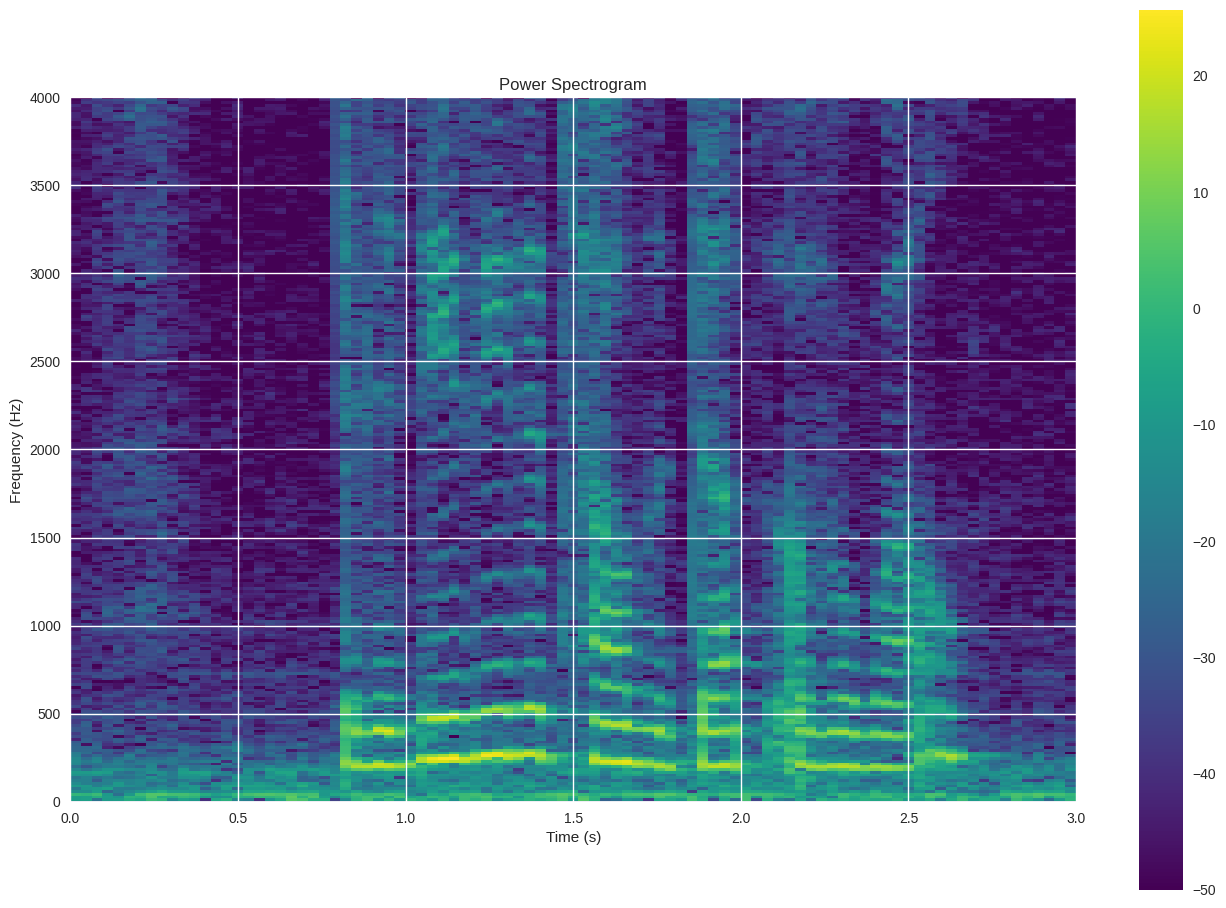

In [217]:
# spectogram in time (s) and frequency (Hz)
f_bins = np.arange(NFFT//2+1)
time_seconds = np.arange(7,10,hop_size/sample_rate)
ax = show_specgram(10*np.log10(np.abs(DFT)**2),ratio=0.7,
                   limits=[0,3,sample_rate/2,0],cmin=-50)
ax.set_title('Power Spectrogram')
ax.set_ylabel('Frequency (Hz)')
ax.set_xlabel('Time (s)')

### Observation

As mentioned before, the time axis for the selected audio portion goes from 0 to 3 seconds, instead of 7 to 10 seconds.

### **Exercise 4**: Librosa representations (STFT)

Let's first check the librosa documentation: https://librosa.org/doc/main/generated/librosa.stft.html?highlight=stft#librosa-stft

The most important parameters are:
  - **win_length** - this is the size of our analysis window (in samples)
  - **hop_length** - this is the hop size of our analysis window (in samples), usually this is chosen to be half the window size
  - (**n_fft**) - this is the used "FFT size", which can be bigger than the **win_length** (but should be a power of two, such that the Fast Fourier Transform (FFT) algorithm can be used internally)
  

### Tasks:
* Use librosa to represent the power spectrogram of the signal, as we computed manually in the last exercise.

Text(0.5, 0, 'Time (s)')

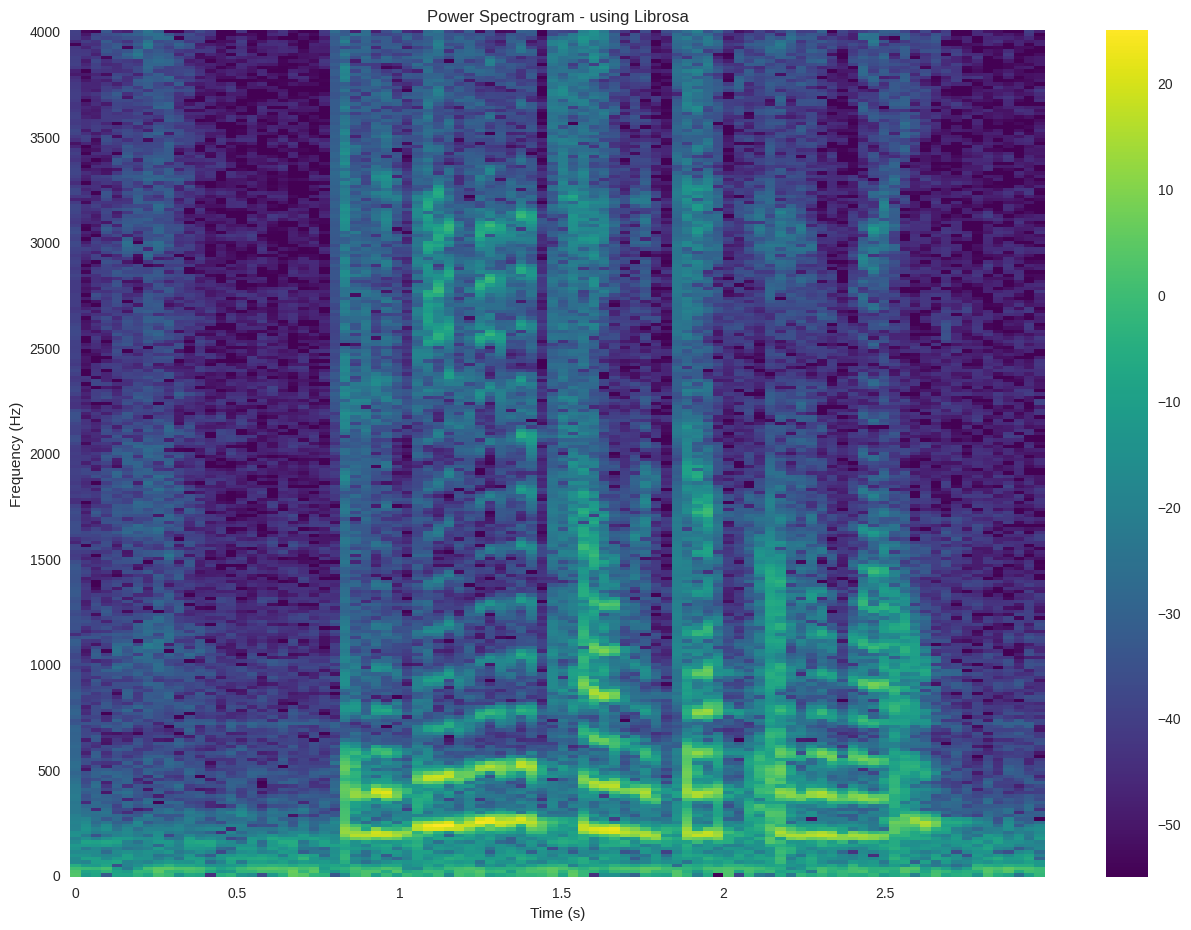

In [218]:
# STFT and spectogram computation with libraries
X = librosa.stft(y=cut_audio, n_fft=frame_length, hop_length=hop_size)
X_pow_db = librosa.power_to_db(np.abs(X)**2)

w, h = plt.figaspect(0.7)
plt.figure(figsize=(w*2,h*2))
librosa.display.specshow(X_pow_db, sr=sample_rate, hop_length=hop_size,
                         x_axis='time', y_axis='linear', cmap='viridis');
plt.colorbar()
plt.title('Power Spectrogram - using Librosa')
plt.ylabel('Frequency (Hz)')
plt.xlabel('Time (s)')

* Experiment with different values of frame length and hop size and discuss the results.

In [219]:
# original values: frame_length= 512   hop_size = 256
def spectrogram_voice_plot(frame_length, hop_size):

  print("Time bins: " +  str(int(np.ceil((len(cut_audio) - frame_length) / hop_size) + 1)) + " (agains the previous 93)" )
  print("Frequency bins: " + str(frame_length//2 + 1)+ " (agains the previous 257)")

  X_2 = librosa.stft(y=cut_audio, n_fft=frame_length, hop_length=hop_size)  # win_length = n_fft (default)
  X_pow_db_2 = librosa.power_to_db(np.abs(X_2)**2)

  w, h = plt.figaspect(0.7)
  plt.figure(figsize=(w*2,h*2));
  librosa.display.specshow(X_pow_db_2, sr=sample_rate, hop_length=hop_size, x_axis='time', y_axis='linear', cmap='viridis');
  plt.colorbar()
  plt.title(f'Power Spectrogram - different parameters (frame length {frame_length}, hop size {hop_size})')
  plt.ylabel('Frequency (Hz)')
  plt.xlabel('Time (s)')

### Basic notions

In a spectrogram, we find that the time resolution is

$$t_{\text{res}}=\frac{\text{hop size}}{f_s}$$

while the frequency resolution is

$$f_{\text{res}}=\frac{f_s}{\text{frame length}}$$

Where $f_s$ is the sample rate. In addition to that, the number of time bins is:

$$n_{t_{\text{bins}}}= ⌈ \frac{\text{signal length} - \text{frame length}}{\text{hop size}} \rceil + 1$$

while the number of frequency bins is:

$$n_{f_{\text{bins}}}=\text{frame length}//2+1$$

We need to take into account the overlapping:

$$\frac{\text{frame length} - \text{hop size}}{\text{frame length}}$$

The more overlapping occurs, the more consecutive results will blend: the resulting spectogram will be more smooth (or blurred) due to the fact that the samples are processed in more temporal frames.
The immediate consequence is that it is more difficult to enhance fast variations in time.

This limitation is related to both time and frequency resolution.
In an ideal scenario, we would like to take small hop sizes and great frame lengths: the result is that great overlapping occurs (and so the spectogram is blurred).
In the end, there is a trade-off between time-frequency resolution and spectogram clarity.

<span style="color: red;">I don't fully agree with you! If you pick a 2 second window with 90% overlaping and you have silence until 1.5 seconds that a sound event starts, you will have energy from the very first frame due to the large window size! So time resolution depends on both, the window and the hop size!</span>

**Case 1 - Decrease the frame length and hop size to 1/4 of the original value**

Time bins: 374 (agains the previous 93)
Frequency bins: 65 (agains the previous 257)


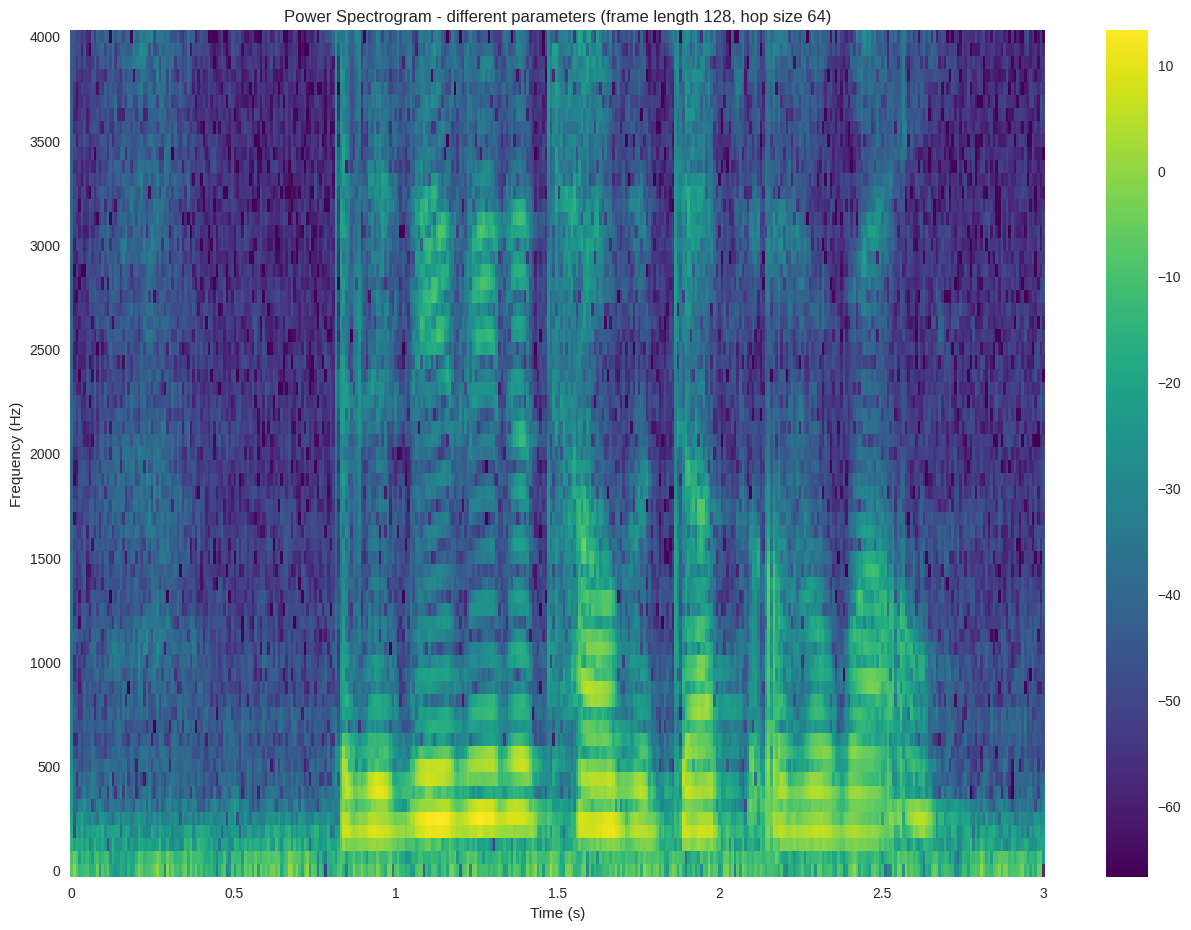

In [220]:
# original values: frame_length= 512   hop_size = 256
frame_length = int(512/4)
hop_size = int(256/4)

spectrogram_voice_plot(frame_length, hop_size)

In this case, we increased the time resolution, and decreased the frequency resolution.
The overllaping factor remains the same.

We can see that there is a lot of information in the time axis, being able to capture more details than before.
Take into account that not always it is better to have more details, because if the time changes are very slow, the information gained might be redundant.

Regarding the frequency, we find that there is much less information: it may be harder than before to distinguish the harmonics.

If we look at the number of bins, we find out that before we had 257 and 93 bins for frequency and time respectively, but now we have 65 and 374, changing the balance completely.

**Case 2 - Increase the frame length and hop size to x2 of the original values**

Time bins: 46 (agains the previous 93)
Frequency bins: 513 (agains the previous 257)


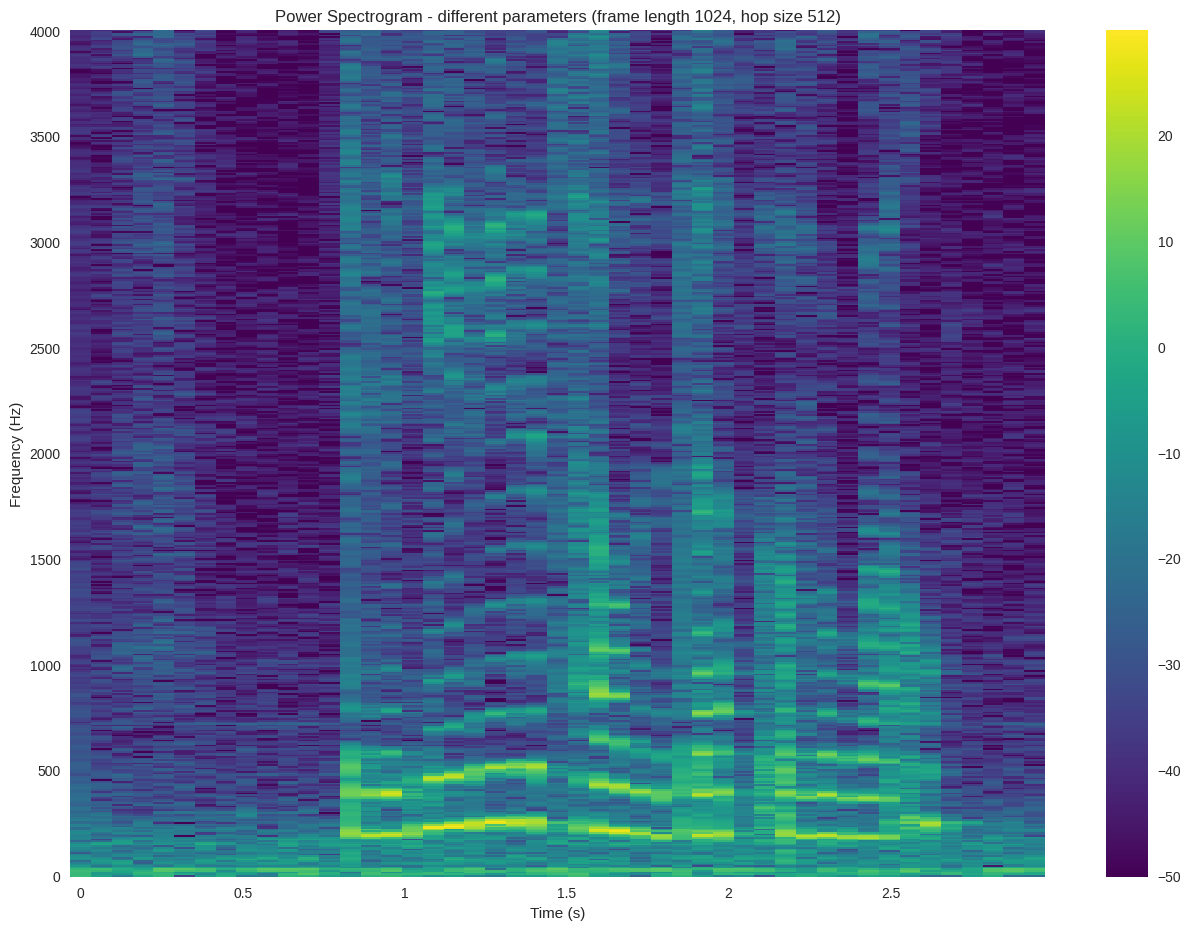

In [221]:
# original values: frame_length= 512   hop_size = 256
frame_length = int(512*2)
hop_size = int(256*2)

spectrogram_voice_plot(frame_length, hop_size)

In this case, we find the opposite scenario.
Now, the frequency resolution is even better than the original, having much more bins, but the time resolution has decreased
substantially.
We are able to distinguish the harmonics perfectly, but it is true that time changes are perceived less smoothly due to the low time resolution.

**Case 3 - Increasing the frame length and decreasing the overlapping of frames simultaneously**

Time bins: 181 (agains the previous 93)
Frequency bins: 513 (agains the previous 257)


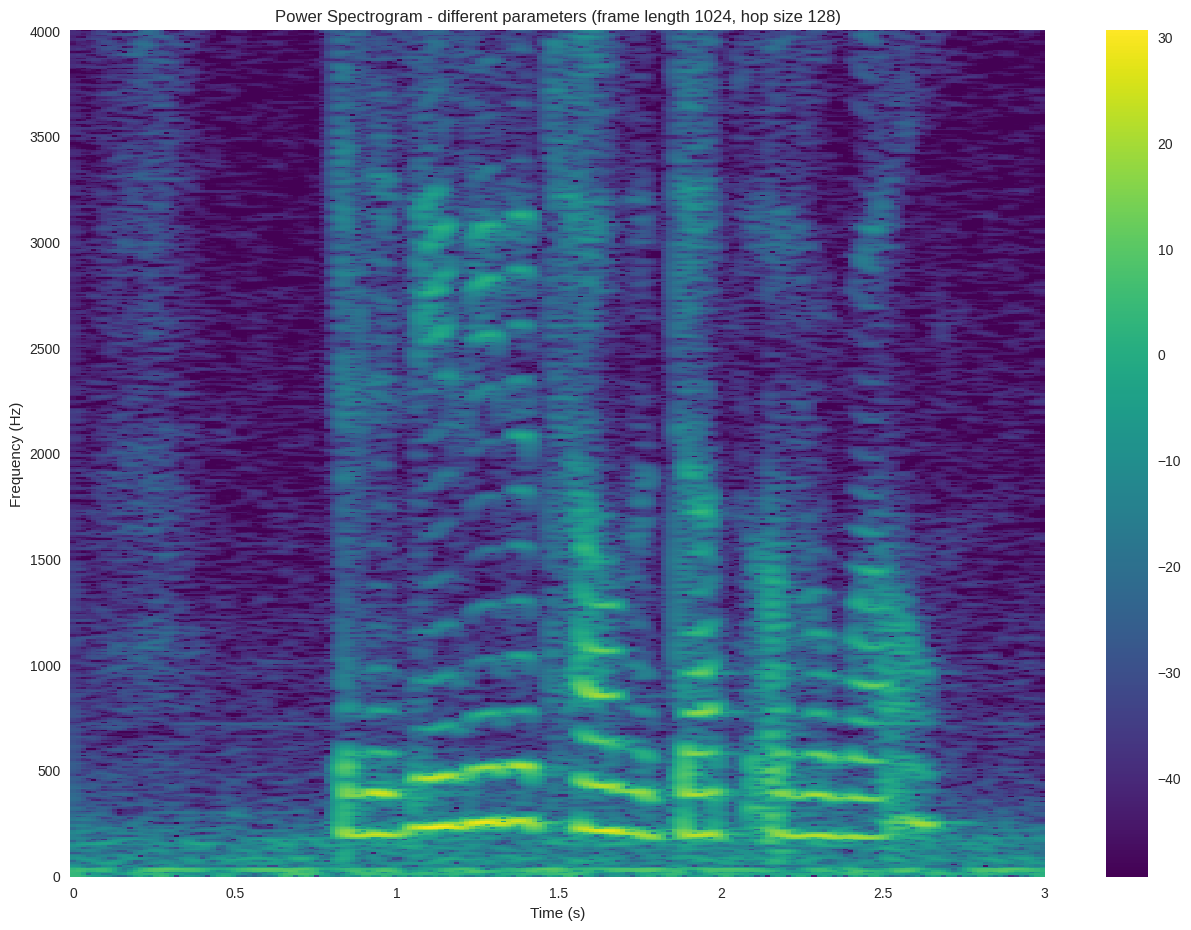

In [222]:
# original values: frame_length= 512   hop_size = 256
frame_length = int(512*2)
hop_size = int(256/2)

spectrogram_voice_plot(frame_length, hop_size)

In this case, we can increase the frame length, decrease the hop size, or both.
To enhance the differences with the original case, we decide to do both with a factor 2, resulting in the values of 1024 and 128 for frame length and hop size respectively.

We see that those changes increase both time and frequency resolution, having a lot of information in the new spectrogram.
On the other hand, we find out this graph to be a little bit blurred along the time axis, seeing that what used to be points now looks like horizontal lines.
This is coherent with the observations done explained before.

<span style="color: red;">Here you have a good trade-off between time and frequency resolution. You see more blurred because you are better tracking the changes in the signal.</span>

### **Exercise 5**: Mel-Spectrograms

Let's first check the librosa documentation: https://librosa.org/doc/main/generated/librosa.feature.melspectrogram.html

The most important parameters are
  - **y** - audio sample vector ($x$)
  - **sr** - sampling rate of the audio signal (in Hz)
  - **n_mels** - number of Mel frequency bands (commonly: 64 or 128)
  - **win_length** - see above (STFT)
  - **hop_length** - see above (STFT)
  - **n_fft** - see above (STFT)

### Tasks:
* Compute the mel spectrogram using librosa. Experiment with different values of the parameters and discuss the results.

**Case 1 - Setting number of Mel bands to be generated as 40**

Take 40 mel bands is a typical number used as a best practice.

Text(0, 0.5, 'Frequency (Hz)')

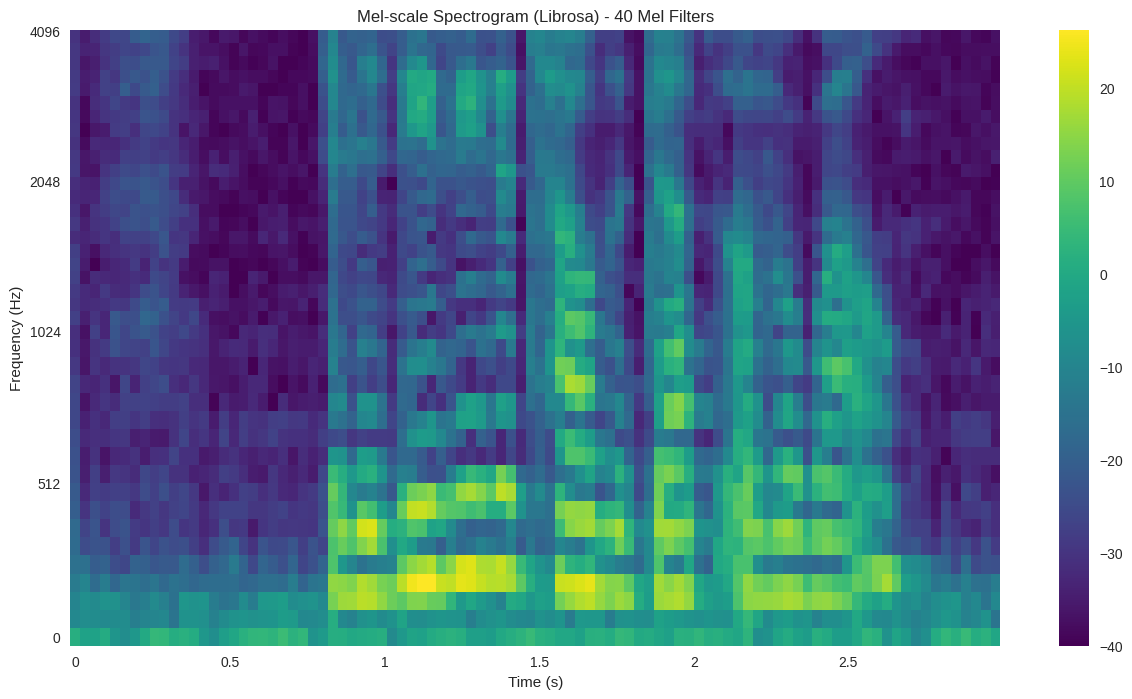

In [223]:
# original values of frame length and hop size
frame_length = 512
hop_size = 256

# Mel spectogram parameter (number of bands) and computation
n_mels = 40
X_mel = librosa.feature.melspectrogram(y=cut_audio, sr=sample_rate,
            n_fft=frame_length, hop_length=hop_size, n_mels=n_mels,
            power=2, norm=None) # win_length = n_fft (default)

plt.figure(figsize=(15,8));
librosa.display.specshow(librosa.power_to_db(X_mel), sr=sample_rate,
                         hop_length=hop_size, x_axis='time', y_axis='mel',
                         fmax=sample_rate/2, cmap='viridis');
plt.clim(-40,None);
plt.colorbar();
plt.title('Mel-scale Spectrogram (Librosa) - 40 Mel Filters');
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')

**Case 2 - Decreasing number of Mel bands to 10**

Text(0, 0.5, 'Frequency (Hz)')

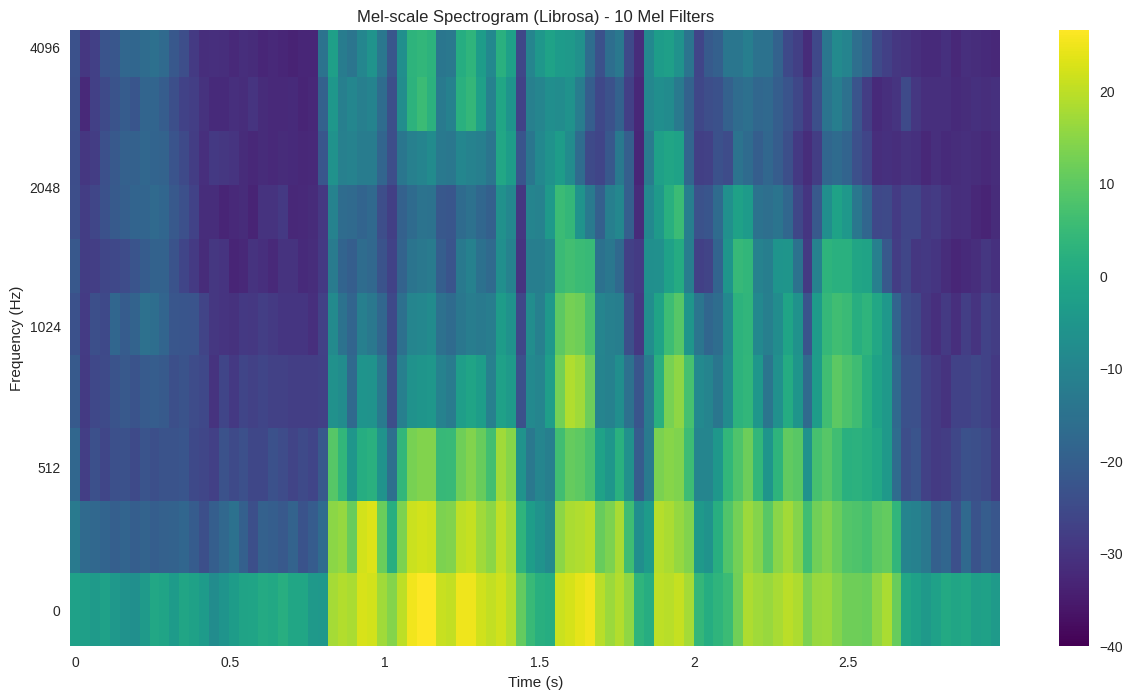

In [224]:
# Mel spectogram parameter (number of bands) and computation
n_mels = 10
X_mel_10 = librosa.feature.melspectrogram(y=cut_audio, sr=sample_rate,
            n_fft=frame_length, hop_length=hop_size, n_mels=n_mels,
            power=2, norm=None) # win_length = n_fft (default)

plt.figure(figsize=(15,8));
librosa.display.specshow(librosa.power_to_db(X_mel_10), sr=sample_rate,
                         hop_length=hop_size, x_axis='time', y_axis='mel',
                         fmax=sample_rate/2, cmap='viridis');
plt.clim(-40,None);
plt.colorbar();
plt.title('Mel-scale Spectrogram (Librosa) - 10 Mel Filters');
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')

### Mel-scale representations

Mel-scale is useful to represent the information in a way similar to how the hearing system works, which is suited for speech signals.
Specifically, lower frequency bands are narrower with respect to higher frequency bands, which group wider frequency ranges, emulating the logarithmic ear behaviour.
The advantage of such a technique is that focuses on low-frequency content (unrelated to any music information), which is suited for speech signals and pitch detection applications.

The difference with respect to the STFT-based representations is the logarithmic mapping of the frequencies:

$$\text{mel}(f) = \frac{1000}{\log 2} \log \left(1+\frac{f}{1000} \right)$$

The frequency resolution of this kind of representation is strictly related to the number of Mel bands: the more we divide the entire frequency range of interest (0-4000 Hz), the more information we are able to display.
Larger Mel bands (lower number of Mel bands) average the frequency content with different weights, which results in lower frequency resolution.

We can get better results increasing the number of Mel bands, but up to a certain point the frequency resolution is so high that the spectogram representation presents some "empty" rows.
This is more noticeable in low frequencies, where the resolution is higher due to the nature of the scale.

### Now let's perform a similar analysis with a music signal ("oboe_c6.wav").


In [225]:
!wget -P sample_data/ https://ccrma.stanford.edu/workshops/dsp2008/sound-library/oboe/Oboe1/Oboe-C6.wav

oboeC6 , sr = librosa.load('sample_data/Oboe-C6.wav', sr=None)
IPython.display.display(IPython.display.Audio(oboeC6, rate=sr))

--2025-03-17 18:04:41--  https://ccrma.stanford.edu/workshops/dsp2008/sound-library/oboe/Oboe1/Oboe-C6.wav
Resolving ccrma.stanford.edu (ccrma.stanford.edu)... 171.64.197.141
Connecting to ccrma.stanford.edu (ccrma.stanford.edu)|171.64.197.141|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 94542 (92K) [audio/x-wav]
Saving to: ‘sample_data/Oboe-C6.wav.3’

Oboe-C6.wav.3       100%[===================>]  92.33K   267KB/s    in 0.3s    

2025-03-17 18:04:42 (267 KB/s) - ‘sample_data/Oboe-C6.wav.3’ saved [94542/94542]




**Case 1 - Setting number of Mel bands to be generated as 40**

Text(0, 0.5, 'Frequency (Hz)')

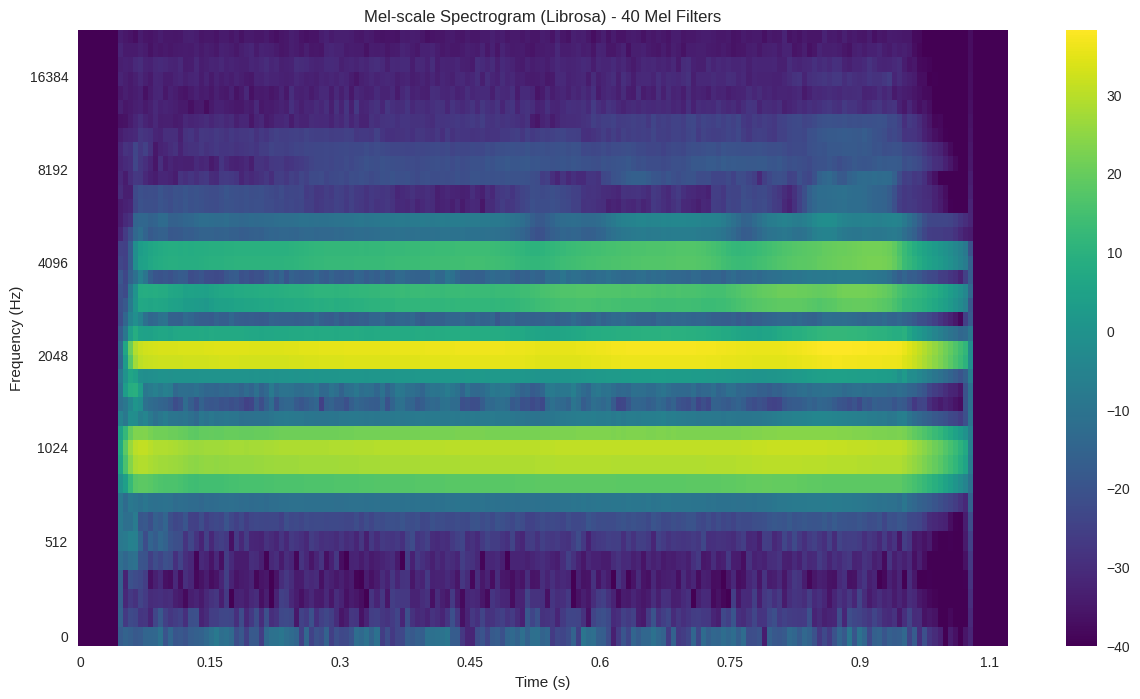

In [226]:
# Mel spectogram parameter (number of bands) and computation
n_mels = 40
X_ob_mel = librosa.feature.melspectrogram(y=oboeC6, sr=sr,
            n_fft=frame_length, hop_length=hop_size, n_mels=n_mels,
            power=2, norm=None) # win_length = n_fft (default)

plt.figure(figsize=(15,8));
librosa.display.specshow(librosa.power_to_db(X_ob_mel), sr=sr,
                         hop_length=hop_size, x_axis='time', y_axis='mel',
                         fmax=sr/2, cmap='viridis');
plt.clim(-40,None);
plt.colorbar();
plt.title('Mel-scale Spectrogram (Librosa) - 40 Mel Filters');
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')

**Case 2 - Decreasing number of Mel bands to 10**

Text(0, 0.5, 'Frequency (Hz)')

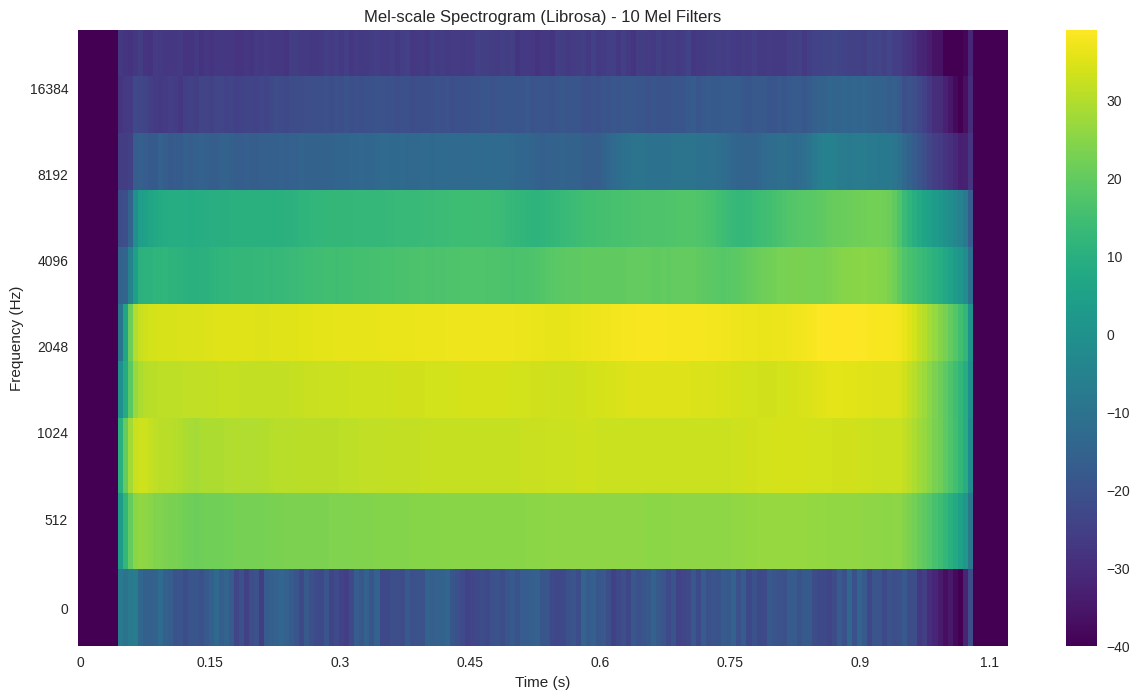

In [227]:
# Mel spectogram parameter (number of bands) and computation
n_mels = 10
X_ob_mel_10 = librosa.feature.melspectrogram(y=oboeC6, sr=sr,
            n_fft=frame_length, hop_length=hop_size, n_mels=n_mels,
            power=2, norm=None) # win_length = n_fft (default)

plt.figure(figsize=(15,8));
librosa.display.specshow(librosa.power_to_db(X_ob_mel_10), sr=sr,
                         hop_length=hop_size, x_axis='time', y_axis='mel',
                         fmax=sr/2, cmap='viridis');
plt.clim(-40,None);
plt.colorbar();
plt.title('Mel-scale Spectrogram (Librosa) - 10 Mel Filters');
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')

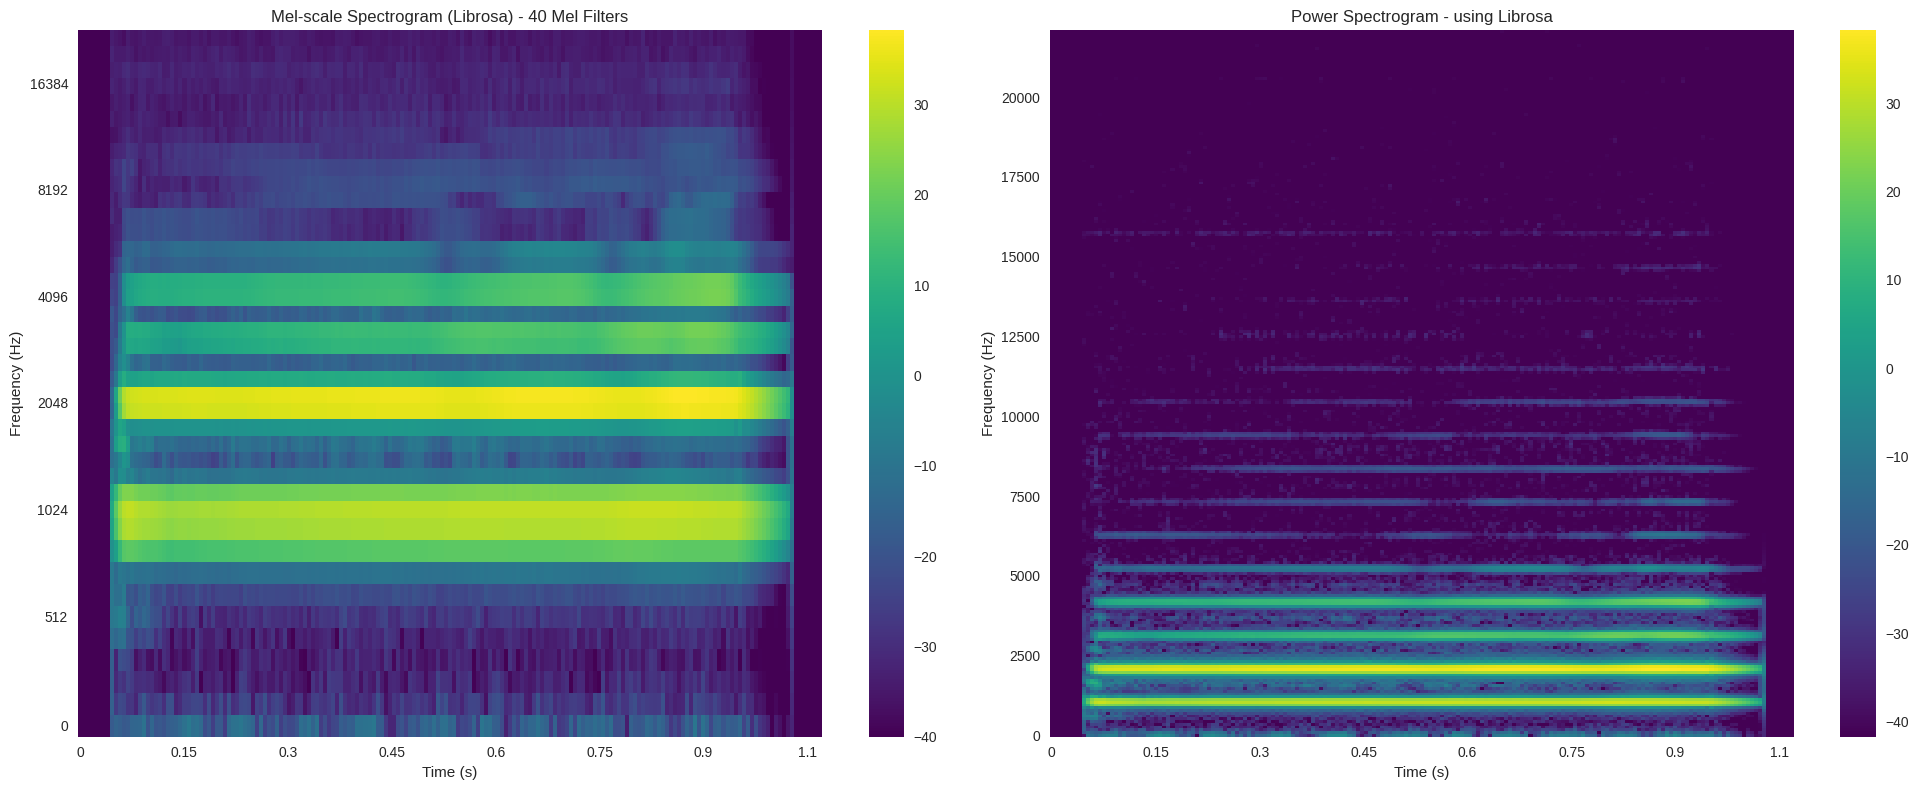

In [228]:
# Comparison between mel graph and normal spectrogram

# Mel plot
n_mels = 40
X_ob_mel = librosa.feature.melspectrogram(y=oboeC6, sr=sr,
            n_fft=frame_length, hop_length=hop_size, n_mels=n_mels,
            power=2, norm=None)

# Normal STFT
X = librosa.stft(y=oboeC6, n_fft=frame_length, hop_length=hop_size)
X_pow_db = librosa.power_to_db(np.abs(X)**2)


plt.figure(figsize=(20, 8))

# First subplot
plt.subplot(1, 2, 1)
librosa.display.specshow(librosa.power_to_db(X_ob_mel), sr=sr,
                         hop_length=hop_size, x_axis='time', y_axis='mel',
                         fmax=sr/2, cmap='viridis')
plt.clim(-40, None)
plt.colorbar()
plt.title('Mel-scale Spectrogram (Librosa) - 40 Mel Filters')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')

# Second subplot
plt.subplot(1, 2, 2)
librosa.display.specshow(X_pow_db, sr=sr, hop_length=hop_size,
                         x_axis='time', y_axis='linear', cmap='viridis')
plt.colorbar()
plt.title('Power Spectrogram - using Librosa')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')

plt.tight_layout()

plt.show()

### Oboe analysis

Previously, we put into light the advantages of the Mel-scale for speech signals and pitch detection.

The capability of finding a pitch may still be useful when analysing sound signals: in this case (single oboe note) it is still possible to distinguish the presence of the root note and its harmonics.
As usual, it varies with the number of bands, which allows to get finer results in frequency: it is obvious that a low number of bands (like 10) is not good for this analysis.

The advantage of this technique is that we can detect pitch and harmonics using a data-reduction based representation (i.e. in comparison with STFT-based representations).
We may want to increase the number of bands to be more precise.

The throwback of such a technique is the lack of musical meaning (which we can found in the CQT).

To dig deeper in details, we compare the plot in mel scale and in linear frequency scale.
We may see that is much easier to notice the first harmonics (the important ones) in the mel plot.
On the other hand, the harmonic relation between the partials is not that clear (while in the linear scale they appear equidistant) and most of the higher harmonics of the instrument are lost in the mel plot, so it's not suitable for deeper analysis of the instrument harmonic distribution.

<span style="color: red;">I don't agree here! YOu are using so few mel coefficients (JUST 10 BINS!) and you hare also retaining some of the harmonic structure. This is not happening in the STFT with only 10 bins. Also, if you add up to 128, you'll perfectly distinguish the harmonic structure!</span>

### **Exercise 6**: Constant-Q Transform

Let's first check the librosa documentation: https://librosa.org/doc/main/generated/librosa.cqt.html

The most important parameters are
  - **y** - audio sample vector ($x$)
  - **sr** - sampling rate of the audio signal (in Hz)
  - **hop_length** - see above (STFT)
  - **f_min** - minimum frequency (we can use the default value of 32.70 Hz which corresponds to the note C1)
  - **n_bins** - total number of frequency bins (e.g., for a frequency resolution of one bin per semitone and 4 octaves, this would be 4 * 12 = 48)
  - **bins_per_octave** - Logarithmic frequency resolution (frequency bins per octave, commonly: 12 or 36)
  - **tuning** - Tuning offset (can be used if known tuning frequency of an audio recording deviates from 440 Hz)

HINTS:

```Num of Octaves = n_bins / bins_per_octave```

```Max Frequency = fmin * 2**() n_bins / bins_per_octave```
  

### Tasks:
* Compute the constant Q transform using librosa.
Experiment with different values of the parameters and discuss the results.

**Case 1 - The default librosa.display.specshow parameter values.**

Text(0.5, 1.0, 'Constant-Q Transform Power Spectrum - default values')

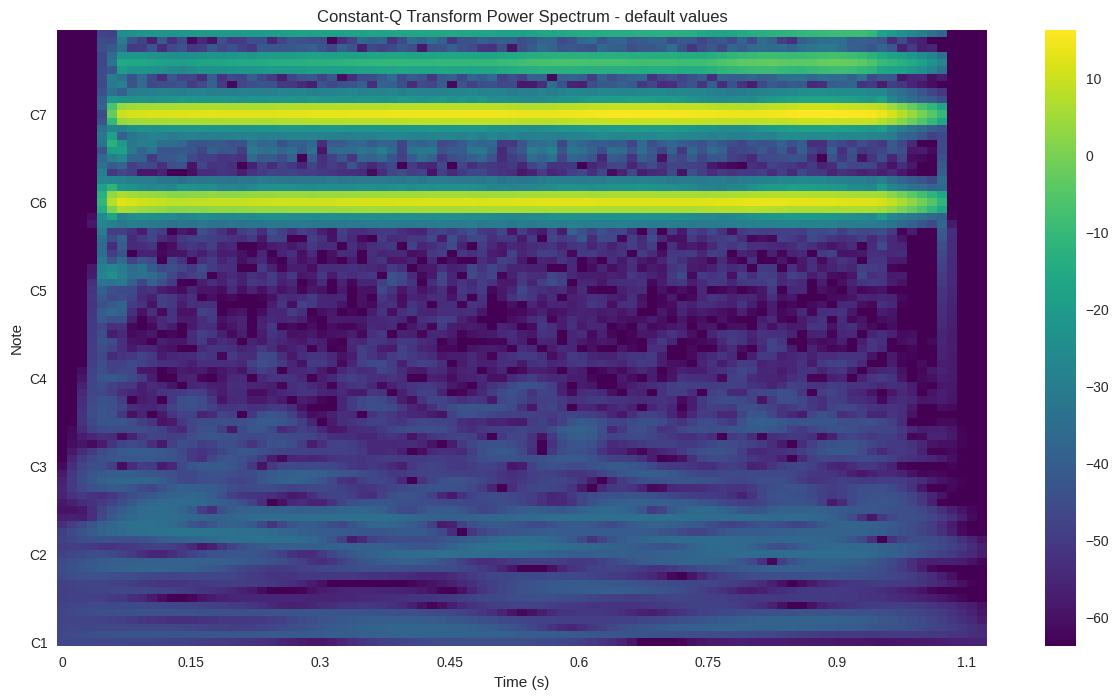

In [229]:
# CQT parameters and computation
f_min = librosa.note_to_hz('C1')
'''
n_octaves = 8       # from C1 to C9
bins_octave = 12    # bin = semitone
n_bins = n_octaves * bins_octave
max_freq = f_min * 2**(n_bins/bins_octave)
'''
C = librosa.cqt(y=oboeC6, sr=sr) # all parameters are the default ones
# hop length is 512 by default, we don't use the previous values (256)
C_db = librosa.amplitude_to_db(np.abs(C))

plt.figure(figsize=(15,8))
librosa.display.specshow(C_db, sr=sr, x_axis='time', y_axis='cqt_note', cmap='viridis')
plt.colorbar()
plt.xlabel('Time (s)')
plt.title('Constant-Q Transform Power Spectrum - default values')

**Case 2 - Limit the frequency range (fmin=Hz(C5)) -  increasing `bins_per_octave` to 24**

Text(0.5, 1.0, 'Constant-Q Transform Power Spectrum - 4 octaves and 24 bins per octave')

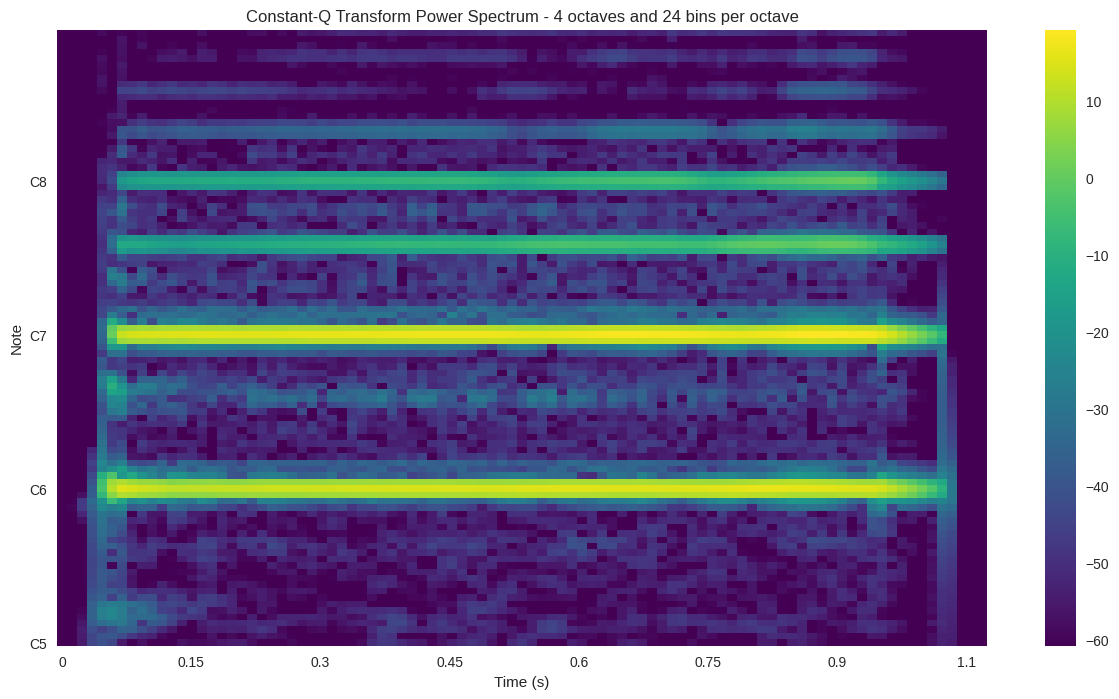

In [230]:
# CQT parameters and computation
f_min = librosa.note_to_hz('C5')
n_octaves = 4       # from C5 to C9
bins_octave = 24    # 2 bins per semitone
n_bins = n_octaves * bins_octave
max_freq = f_min * 2**(n_bins/bins_octave)
C = librosa.cqt(y=oboeC6, sr=sr, fmin=f_min, n_bins=n_bins,
                bins_per_octave=bins_octave)
C_db_2 = librosa.amplitude_to_db(np.abs(C))

plt.figure(figsize=(15,8))
# we specify bins_per_octave and fmin for proper plots
librosa.display.specshow(C_db_2, sr=sr, x_axis='time', y_axis='cqt_note',
                         cmap='viridis', fmin=f_min,
                         bins_per_octave=bins_octave)
plt.colorbar()
plt.xlabel('Time (s)')
plt.title('Constant-Q Transform Power Spectrum - ' + str(n_octaves)+ ' octaves and '+ str(bins_octave) + ' bins per octave')

**Case 3 - Limit the frequency range (fmin=Hz(C5))- decrease the `n_bins` to 53**

Text(0.5, 1.0, 'Constant-Q Transform Power Spectrum - 4.42 octaves and 12 bins per octave')

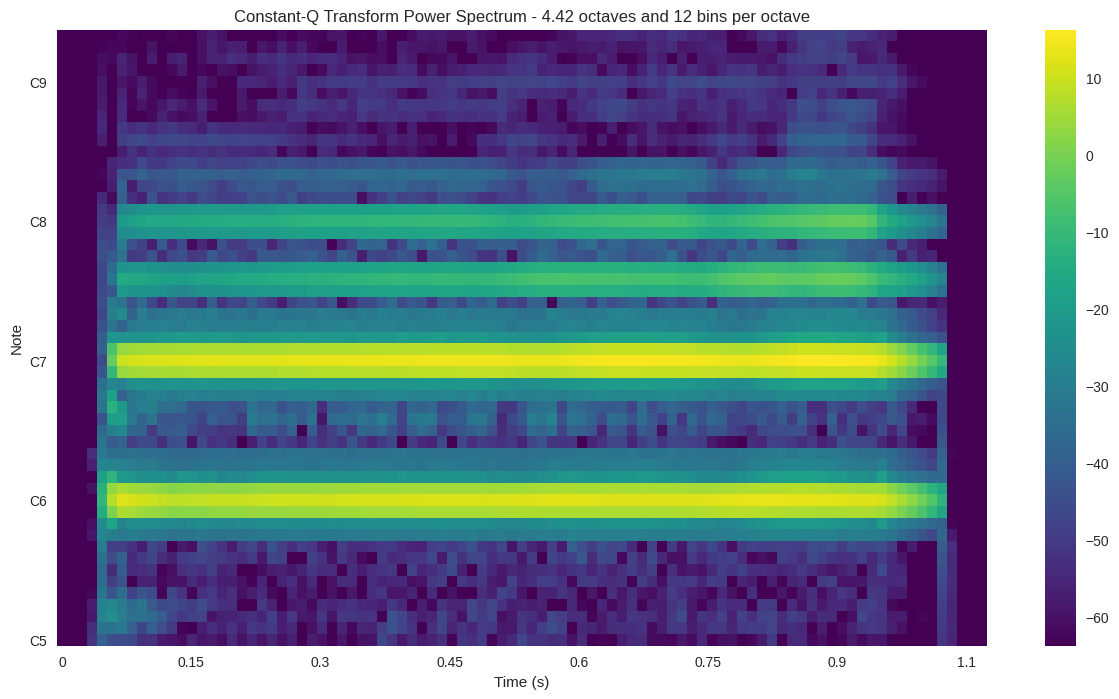

In [231]:
# CQT parameters and computation
f_min=librosa.note_to_hz('C5')
n_bins = 53
bins_octave = 12    # bin = semitone
n_octaves = n_bins / bins_octave
max_freq = f_min * 2**(n_bins/bins_octave)
C = librosa.cqt(y=oboeC6, sr=sr, fmin=f_min,
                     n_bins=n_bins, bins_per_octave=bins_octave)
C_db_3 = librosa.amplitude_to_db(np.abs(C))

plt.figure(figsize=(15,8))
librosa.display.specshow(C_db_3, sr=sr, x_axis='time', y_axis='cqt_note',
                         cmap='viridis', fmin=f_min,
                         bins_per_octave=bins_octave)
plt.colorbar()
plt.xlabel('Time (s)')
plt.title(f'Constant-Q Transform Power Spectrum - {n_octaves:.2f} octaves and {bins_octave} bins per octave')


### CQT Analysis

Similarly to what happens in the Mel-scale, the frequency axis is mapped into a logarithmic scale:

$$f_k = f_0 \ 2^{\frac{k}{b}}$$

Where $b$ is the number of bins per octave and $f_0$ is the starting central frequency (for the first band).

The main difference with respect to the Mel-scale is the focus on the musical meaning behind the frequency axis: each bin may be mapped to represent a semitone, so the frequency content (and the eventual detected pitch) is immediately recognisable as a specific note (instead of bins and bands).
As an extension, it is easy to enchance the harmonical content of the sound (i.e. partials).

This technique can be tuned taking into account the fundamental frequency of the instrument of interest and set $f_0$ to said frequency.
Similarly to Mel bands, increasing $b$ allows us to increasing the frequency resolution of the representation, making it even easier to search for notes.

In our specific cases, we may appreciate an increased resolution with respect to the Mel representation.
In addition to that, this representation feels more useful than the previous ones: as we said, we may easily identify the played note, which is more useful than frequency in musical representation.
Another advantage is that we have better resolution on the fundamental frequencies.

Finally, we can notice that this representation brings data reduction, using only $\frac{\text{number\_of\_bins} \cdot \text{duration}}{\text{hop\_size}} \cdot f_s$ elements.
In our case, we go from 257 bins in frequency (where most of them represent silence) to 96 (where each bin represents a note).
Regarding the time axis, in our case we divide by half the number of bins as this representation uses by default `hop_size=512` against the previously used 256.
Still, this representation is heavier that the Mel-scale one (which had 40 bands in frequency).

In conclusion, each representation is more suited when we want to focus on different aspects, and a trade-off always exist between them.

<span style="color: red;">I am missing a deeper analysis of the bins_per_Octave, n_bins and fmin parameters!</span>

### **Exercise 7**: MFCCs

Let's first check the librosa documentation: https://librosa.org/doc/latest/generated/librosa.feature.mfcc.html#librosa.feature.mfcc

The most important parameters are
  - **y** - audio sample vector ($x$)
  - **sr** - sampling rate of the audio signal (in Hz)
  - **n_fft** - see above (STFT)
  - **hop_length** - see above (STFT)
  - **n_mfcc** - Number of MFC coefficients  

### Tasks:
* Compute MFCCs using librosa. Experiment with different values of the parameters and discuss the results.

**Case 1 - Using the standard librosa.feature.mfcc function on the audio file OSR_us_000_0010_8k.wav (seconds 7 to 10)**

Text(0.5, 1.0, 'Mel-Frequency Cepstral Coefficients (MFCC)  - Voice - 13 components')

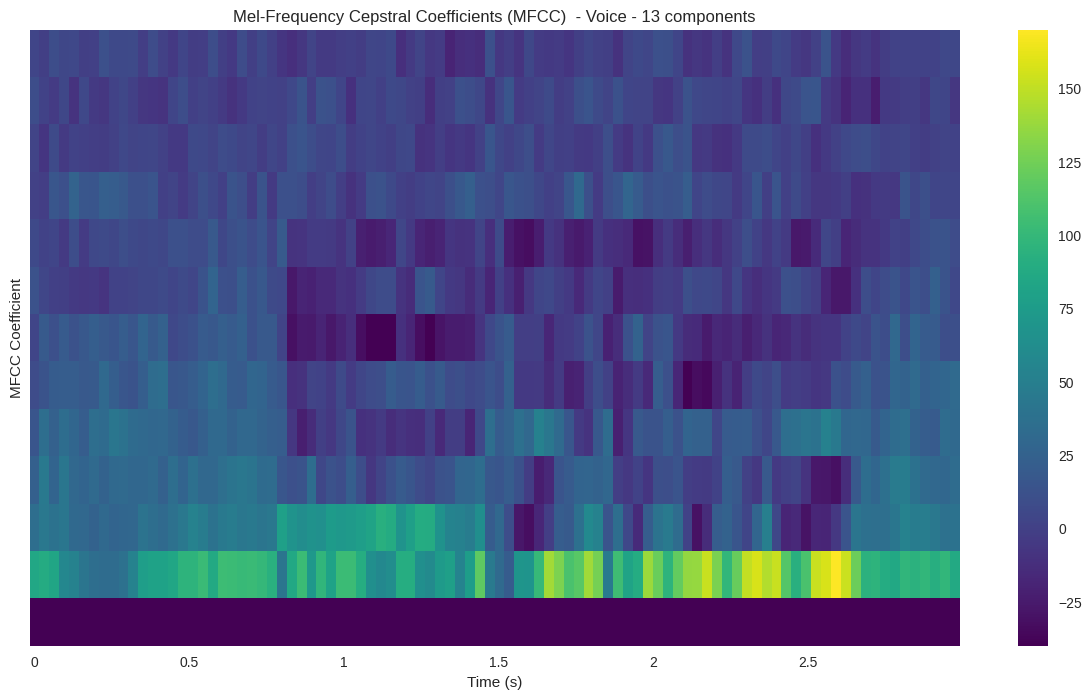

In [232]:
# MFCC parameters and computation
hop_size = 256
frame_length = 512
num_ceps = 13

X_mfcc = librosa.feature.mfcc(y=cut_audio, sr=sample_rate,
            n_fft=frame_length, hop_length=hop_size, n_mfcc=num_ceps)

plt.figure(figsize=(15,8))
librosa.display.specshow(X_mfcc, sr=sample_rate, hop_length=hop_size,
                         x_axis='time', cmap='viridis')
plt.clim(-40,None)
plt.colorbar()
plt.xlabel('Time (s)')
plt.ylabel('MFCC Coefficient')
plt.title('Mel-Frequency Cepstral Coefficients (MFCC)  - Voice - ' + str(num_ceps) + ' components')

**Case 2 - Increasing the number of components to 40**



Text(0.5, 1.0, 'Mel-Frequency Cepstral Coefficients (MFCC) - Voice 40 components')

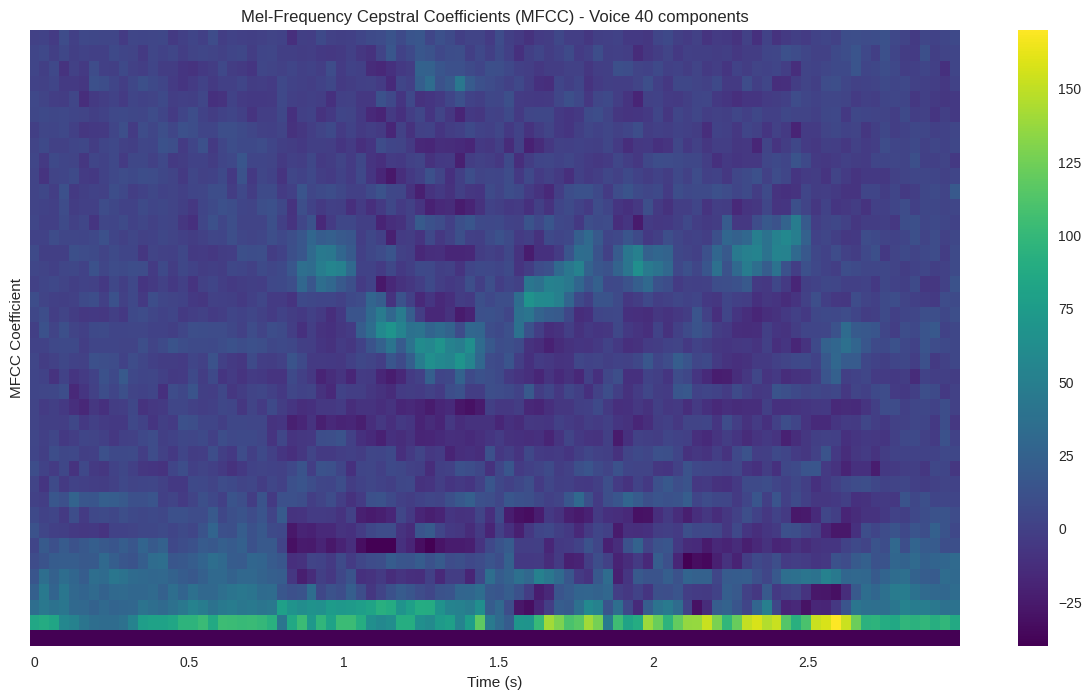

In [233]:
# MFCC parameters and computation
num_ceps = 40
X_mfcc = librosa.feature.mfcc(y=cut_audio, sr=sample_rate,
            n_fft=frame_length, hop_length=hop_size, n_mfcc=num_ceps)

plt.figure(figsize=(15,8))
librosa.display.specshow(X_mfcc, sr=sample_rate, hop_length=hop_size,
                         x_axis='time', cmap='viridis')
plt.clim(-40,None)
plt.colorbar()
plt.xlabel('Time (s)')
plt.ylabel('MFCC Coefficient')
plt.title('Mel-Frequency Cepstral Coefficients (MFCC) - Voice ' + str(num_ceps) + ' components')

The MFCC is obtained by the STFT spectogram, whose energy is filtered by multiple bandpass filters (filterbank) that map the linear frequency axis $f$ into the Mel-scale $\text{mel}(f)$.
The log-power spectrum output of each band (from $1$ to $\text{n}_{\text{MFCC}}$) goes through a DCT, which makes the resulting coefficients decorrelated (better statistical properties).

The MFCC is based on the Mel-scale, and inherits from it the capability of focusing on the lower frequencies.
As usual, the more coefficients we impose, the more the resolution of the frequency content.
This technique is suited for speech and sound-events analysis and allows us to do data reduction by using the first rows only.

The counter part of this technique is that its result is very hard to interpret: when doing the DCT of the Mel spectrogram, we apply a transformation on a frequency representation, which is not intuitive.
In some way, this technique shows any periodicity (in frequency) of the spectrogram.

**Case 3 - Changing the coefficient weighting parameter `lifter` to the number of 2 x number of cepstral coefficients**


Text(0.5, 1.0, 'Mel-Frequency Cepstral Coefficients (MFCC) - Voice 40 components')

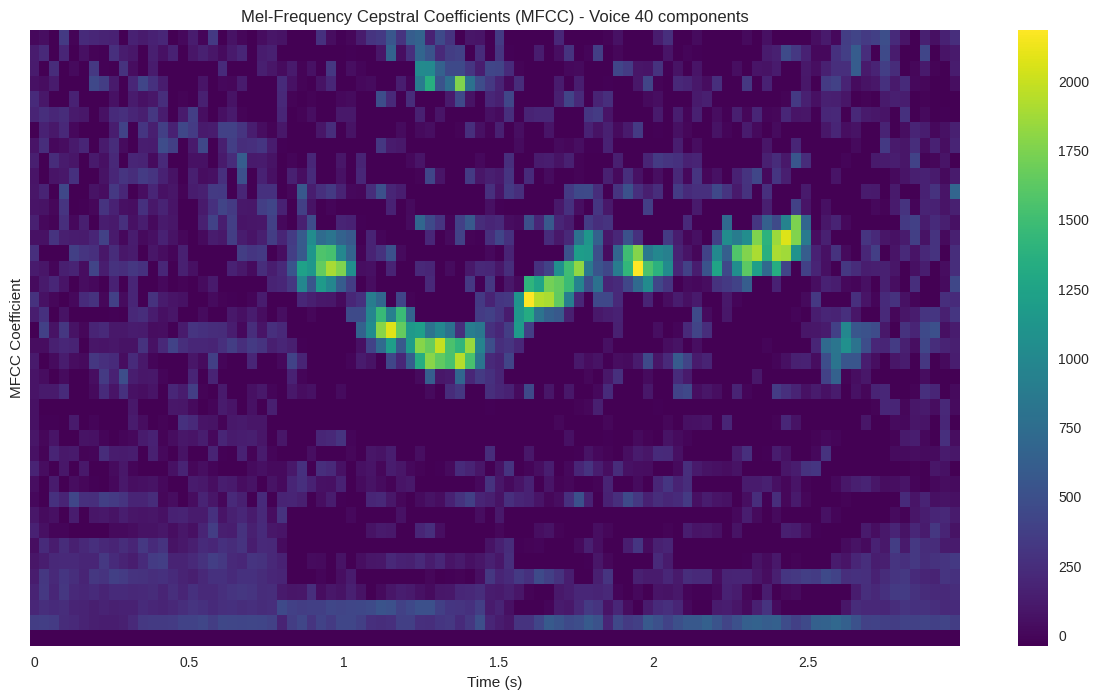

In [234]:
# MFCC parameters and computation
num_ceps = 40
lifter = num_ceps*2
X_mfcc = librosa.feature.mfcc(y=cut_audio, sr=sample_rate,
            n_fft=frame_length, hop_length=hop_size,
            n_mfcc=num_ceps, lifter=lifter)

plt.figure(figsize=(15,8))
librosa.display.specshow(X_mfcc, sr=sample_rate, hop_length=hop_size,
                         x_axis='time', cmap='viridis')
plt.clim(-40,None)
plt.colorbar()
plt.xlabel('Time (s)')
plt.ylabel('MFCC Coefficient')
plt.title('Mel-Frequency Cepstral Coefficients (MFCC) - Voice ' + str(num_ceps) + ' components')

The `lifter` option allows to apply liftering to the MFCC: the high-order coefficients (higher rows = higher frequencies) are more enhanced, which unbalances the original frequency mapping in favour of high frequencies and the higher the liftering coefficients, the more linear the frequency axis gets.

The difference with respect to the previous scenarios is the clear enhancement of high frequencies: what was barely noticeable in the previous plots is now primarly visible.
On the other hand, the low-frequency content is unrecognisable.

**Case 4 - Comparing the oboe_c6.wav audio and simple_piano.wav sound**

/usr/local/lib/python3.11/dist-packages/librosa/feature/spectral.py:2143: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


Text(0.5, 1.0, 'Mel-Frequency Cepstral Coefficients (MFCC) - Oboe')

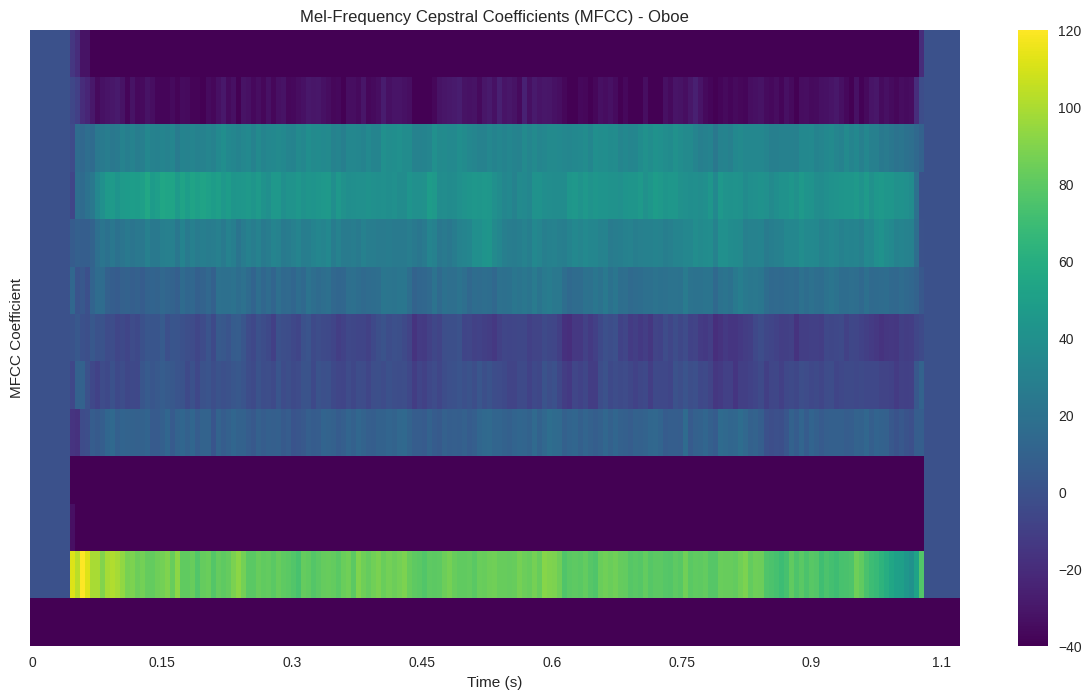

In [235]:
# MFCC parameters and computation
num_ceps=13
oboe_mfcc = librosa.feature.mfcc(y=oboeC6, sr=sr,
            n_fft=frame_length, hop_length=hop_size, n_mfcc=num_ceps)

plt.figure(figsize=(15,8))
librosa.display.specshow(oboe_mfcc, sr=sr, hop_length=hop_size,
                         x_axis='time', cmap='viridis')
plt.clim(-40,None)
plt.colorbar()
plt.xlabel('Time (s)')
plt.ylabel('MFCC Coefficient')
plt.title('Mel-Frequency Cepstral Coefficients (MFCC) - Oboe')

In [236]:
!wget -P sample_data/ https://ccrma.stanford.edu/workshops/dsp2008/sound-library/piano/YamahaH/YamahaH-C6.wav

piano, sr_piano = librosa.load('sample_data/YamahaH-C6.wav', sr=None)
IPython.display.display(IPython.display.Audio(piano, rate=sr_piano))

--2025-03-17 18:04:55--  https://ccrma.stanford.edu/workshops/dsp2008/sound-library/piano/YamahaH/YamahaH-C6.wav
Resolving ccrma.stanford.edu (ccrma.stanford.edu)... 171.64.197.141
Connecting to ccrma.stanford.edu (ccrma.stanford.edu)|171.64.197.141|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 409248 (400K) [audio/x-wav]
Saving to: ‘sample_data/YamahaH-C6.wav.3’

YamahaH-C6.wav.3    100%[===================>] 399.66K   532KB/s    in 0.8s    

2025-03-17 18:04:56 (532 KB/s) - ‘sample_data/YamahaH-C6.wav.3’ saved [409248/409248]



Text(0.5, 1.0, 'Mel-Frequency Cepstral Coefficients (MFCC) - Piano')

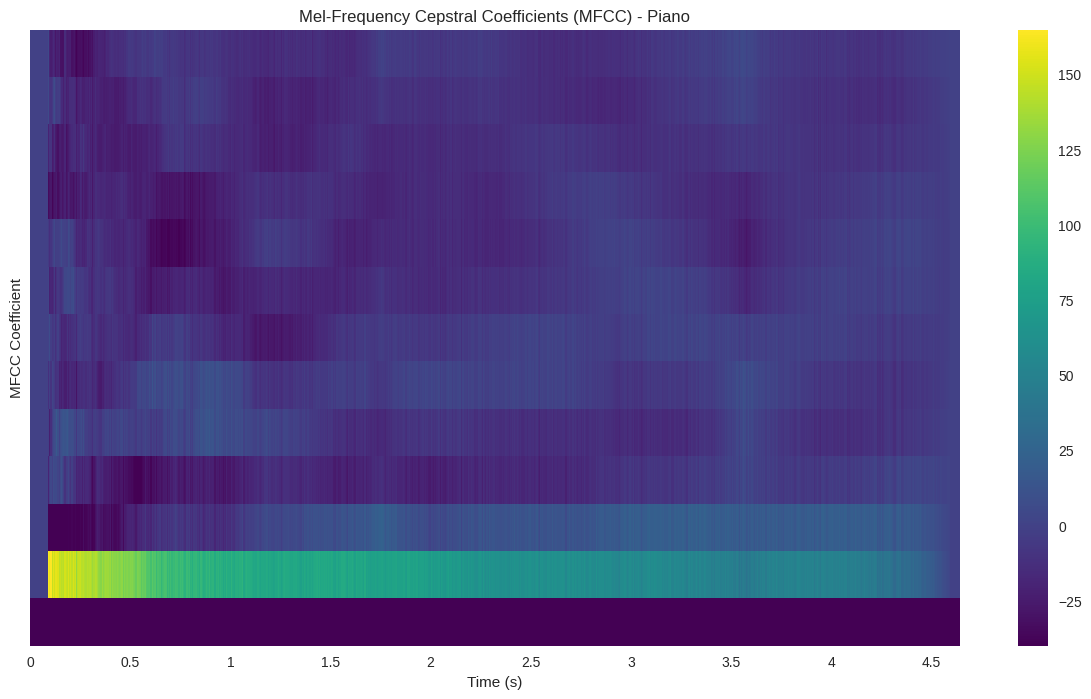

In [237]:
# MFCC parameters and computation
piano_mfcc = librosa.feature.mfcc(y=piano, sr=sr_piano,
            n_fft=frame_length, hop_length=hop_size, n_mfcc=num_ceps)

plt.figure(figsize=(15,8))
librosa.display.specshow(piano_mfcc, sr=sr_piano, hop_length=hop_size,
                         x_axis='time', cmap='viridis')
plt.clim(-40,None)
plt.colorbar()
plt.xlabel('Time (s)')
plt.ylabel('MFCC Coefficient')
plt.title('Mel-Frequency Cepstral Coefficients (MFCC) - Piano')

The spectrograms of the instruments looks periodic in frequency due to the presence of the harmonics.
If we relate this with the previously explained behaviour of the DCT, we expect to obtain most of the energy of the spectrum in just few components that tell us about that periodicity in the linear-frequency spectrogram.

We can see that this is what we obtain.
The oboe sound is richer in high frequency components (note played is at around 1 KHz), while the piano sound is richer in low frequency components.
The frequency mapping (from linear to Mel-scale) is almost linear in the low frequency range, while it is not the same for high frequencies.
Therefore, in this process, any periodicity in high frequencies may not be kept well as for low frequencies.
This observation suggests that if a sound has only low frequency harmonic content, the resulting MFCC plot is clearer.

The MFCC plots we obtained from oboe and piano sounds seem to confirm the previous observation.
In addition to that, we remind that the oboe sound is more noisy due to the nature of wind instruments.
Consequently, the frequency periodicity of the oboe is usually more noisy than in the piano.

In conclusion, with this feature may be much easier to distinguish between music and speech: in one case we only expect lower and sharper components, while in the other the spectrum is more dense and blurred.